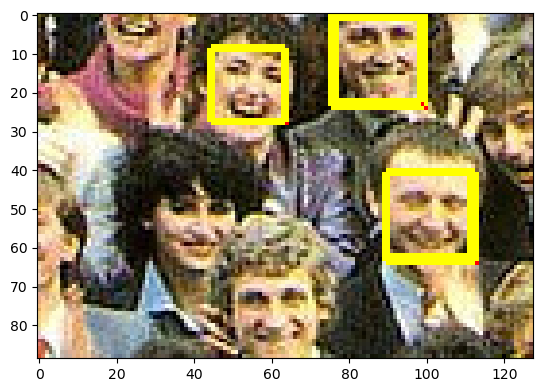

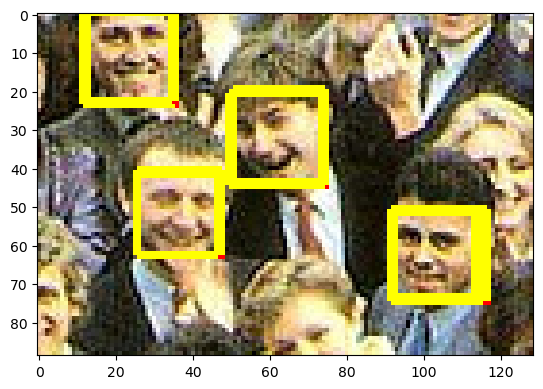

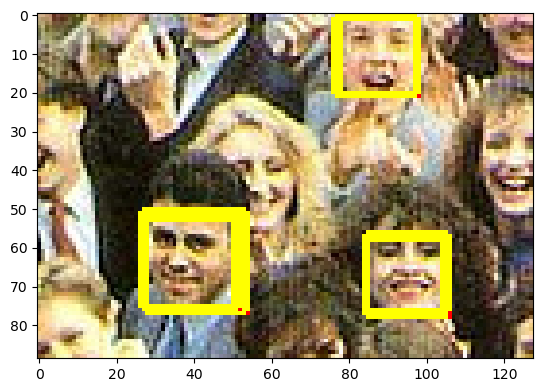

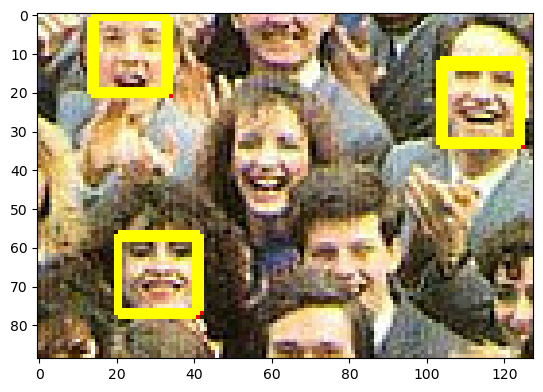

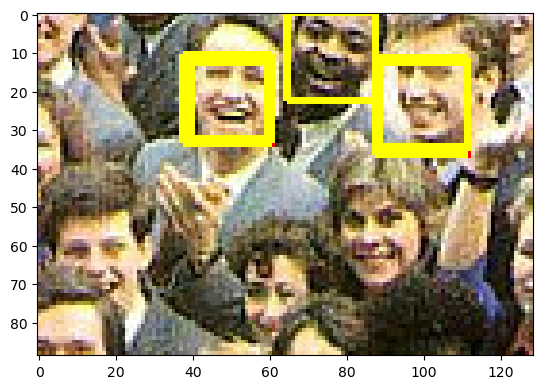

...

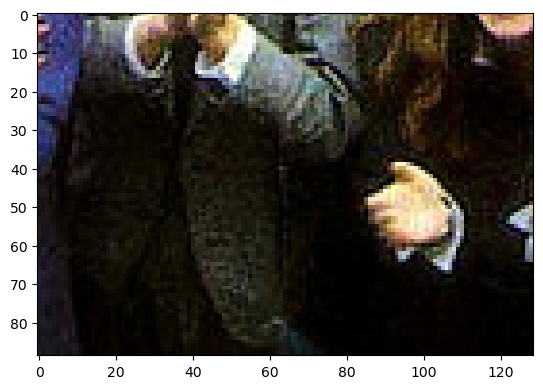

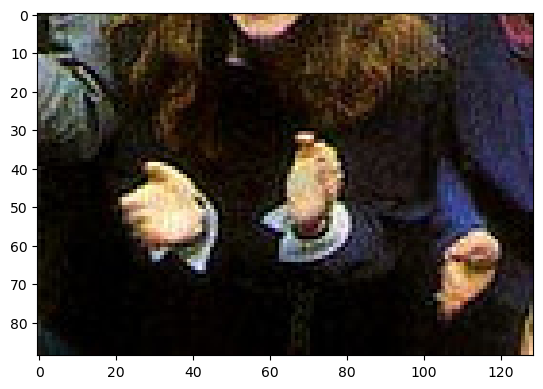

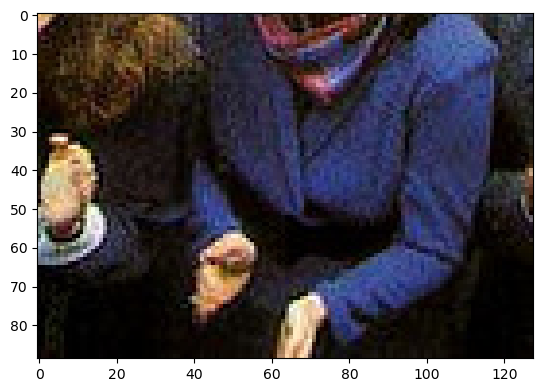

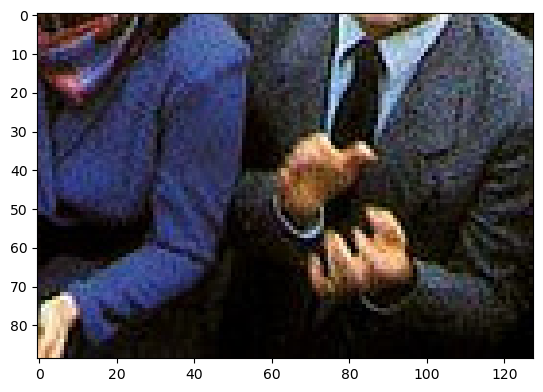

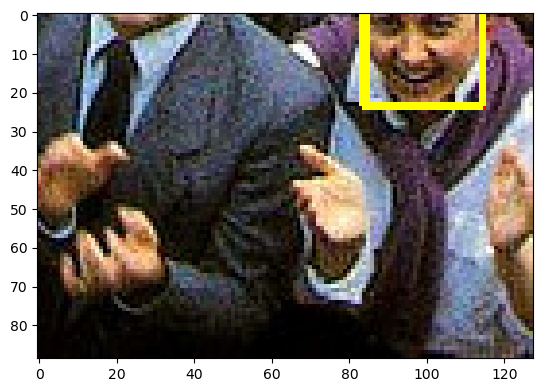

In [8]:
from landpy.models.face_tracker import FaceTracker
from landpy.models.expression_detector import ExpressionDetector
from landpy import ImageLand, Debugger, SquareMarks
import numpy as np

d = Debugger()
m1 = FaceTracker(d)
m2 = ExpressionDetector(d)
im = ImageLand('files/happy crowd.jpg', d)
faces=[]
for i in range(9):
    for j in range(9):
        k = 1/10
        im.make_checkpoint()
        im.zoom(SquareMarks(k*i, k*(i+2), k*j, k*(j+2)))
        faces_in_rec = m1.detect_faces(im, treshhold=0.9)
        for ii in range(len(faces_in_rec)):
            sq = SquareMarks()
            sq.zoom(SquareMarks(k*i, k*(i+2), k*j, k*(j+2)))
            sq.set_marks(faces_in_rec[ii].minX(), faces_in_rec[ii].maxX(), faces_in_rec[ii].minY(), faces_in_rec[ii].maxY())
            sq.retrace()
            faces.append(sq)
            im = im+faces_in_rec[ii]
            #(im+faces_in_rec[0]).show()
        im.show()
        im.undo()

In [9]:
indices_to_remove = []
for i in range(len(faces)):
    for j in range(i+1, len(faces)):
        sub = faces[i].subscription(faces[j])
        if sub is not None and sub.area() > 0.92*(min(faces[i].area(), faces[j].area())):
            if faces[i].area() < faces[j].area():
                indices_to_remove.append(i)
            else:
                indices_to_remove.append(j)
faces = [faces[i] for i in range(len(faces)) if i not in indices_to_remove]

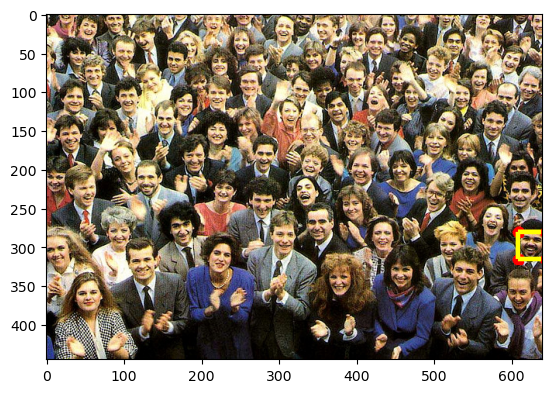

In [3]:
(im+faces[67]).show()

In [10]:
len(faces)

72

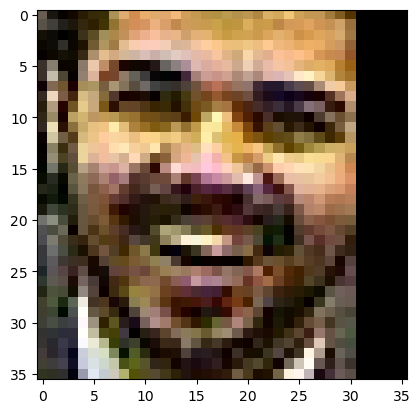

In [4]:
imm = im.copy(save_trace=False).zoom(faces[67], save_trace=False)
(imm).show()

In [6]:
a = {}
a['a'] = 1
a

{'a': 1}

72
1/1 [==============================] - 0s 46ms/step


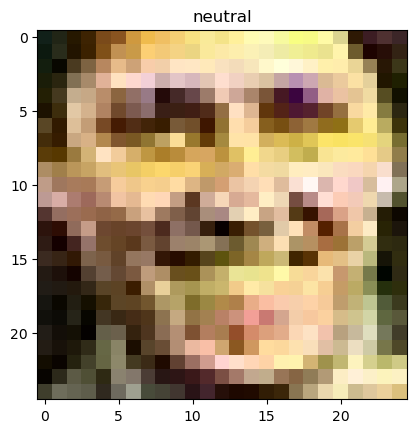

1/1 [==============================] - 0s 44ms/step


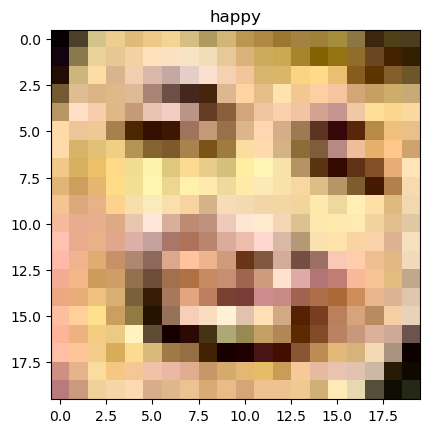

1/1 [==============================] - 0s 45ms/step


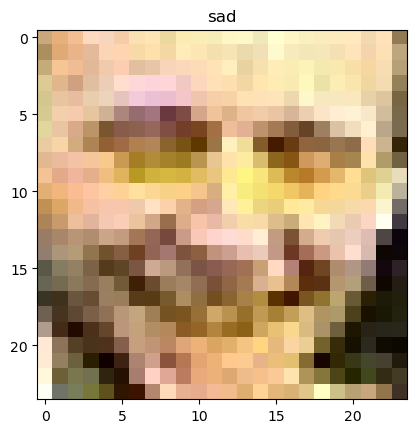

1/1 [==============================] - 0s 45ms/step


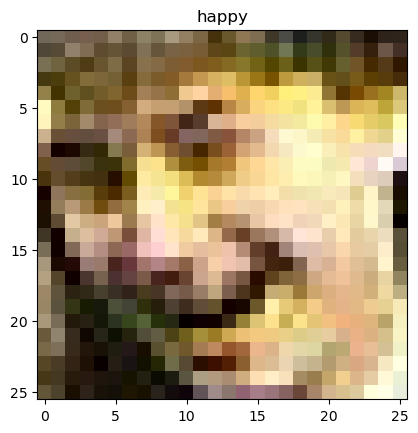

1/1 [==============================] - 0s 60ms/step


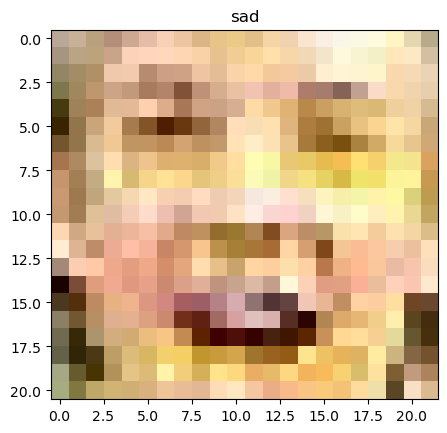

1/1 [==============================] - 0s 49ms/step


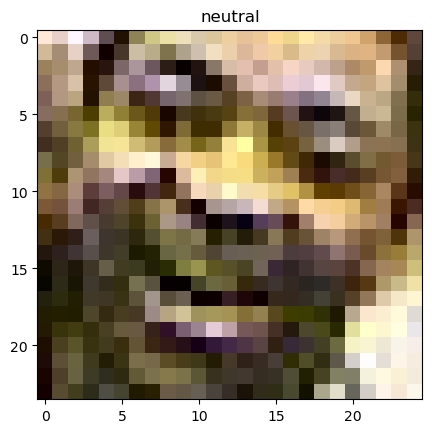

1/1 [==============================] - 0s 50ms/step


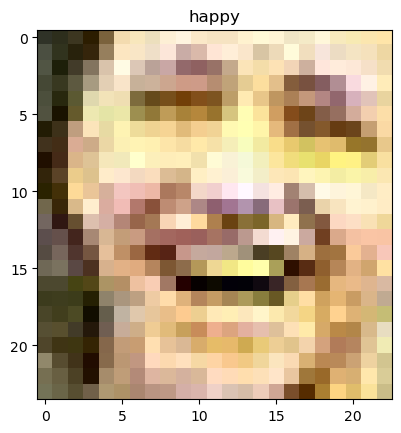

1/1 [==============================] - 0s 54ms/step


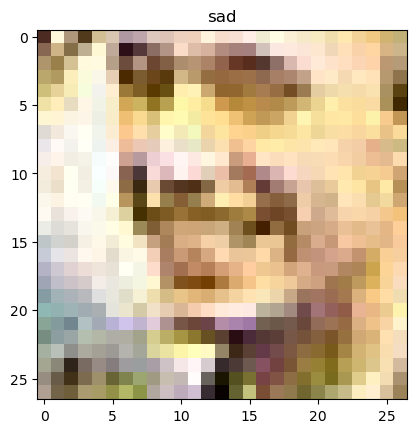

1/1 [==============================] - 0s 40ms/step


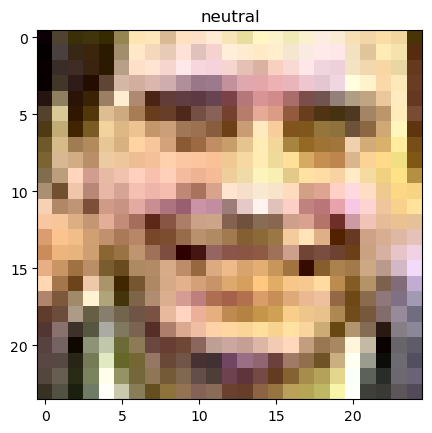

1/1 [==============================] - 0s 46ms/step


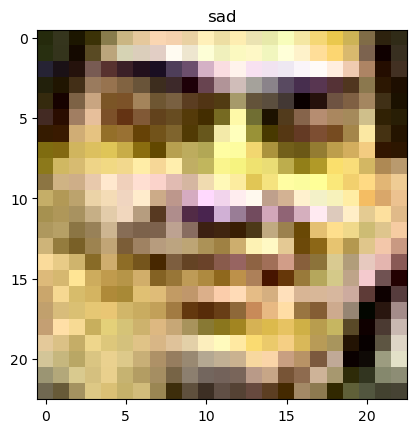

1/1 [==============================] - 0s 43ms/step


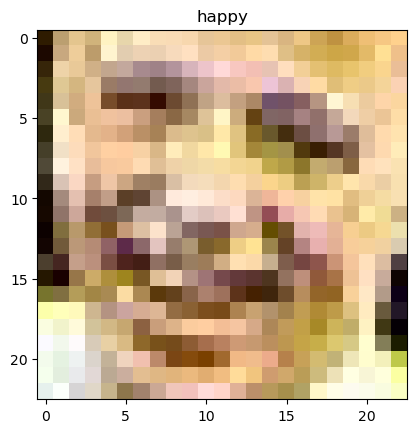

1/1 [==============================] - 0s 40ms/step


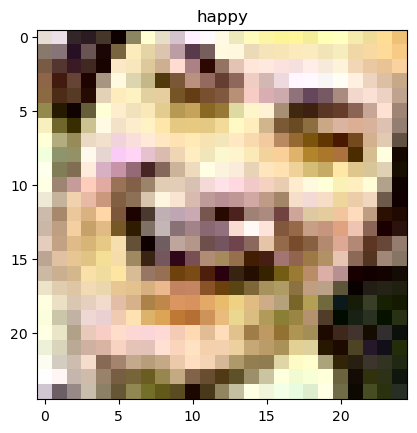

1/1 [==============================] - 0s 38ms/step


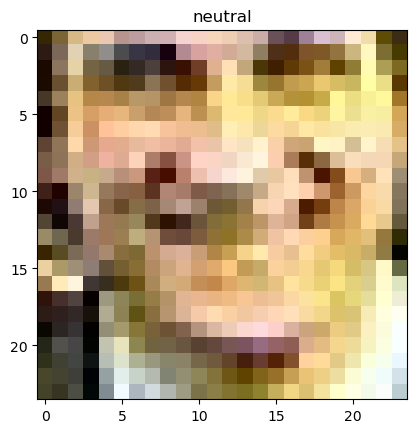

1/1 [==============================] - 0s 36ms/step


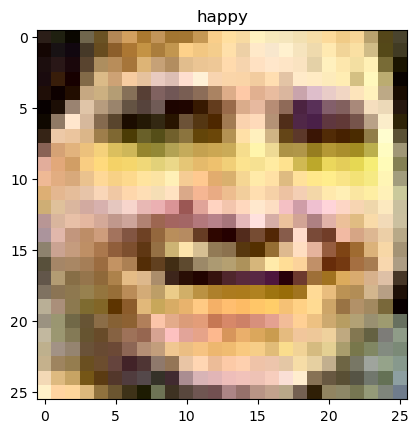

1/1 [==============================] - 0s 37ms/step


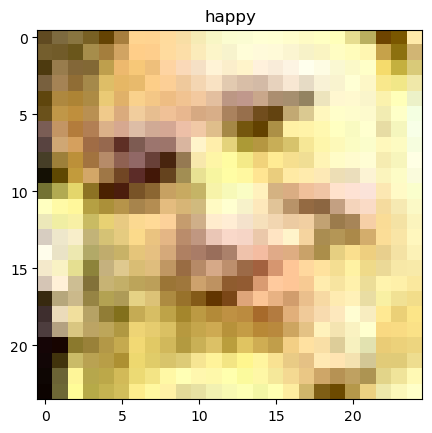

1/1 [==============================] - 0s 42ms/step


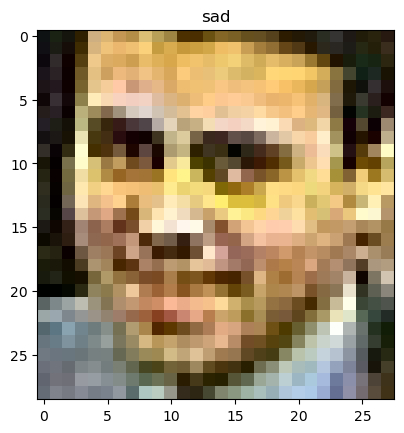

1/1 [==============================] - 0s 41ms/step


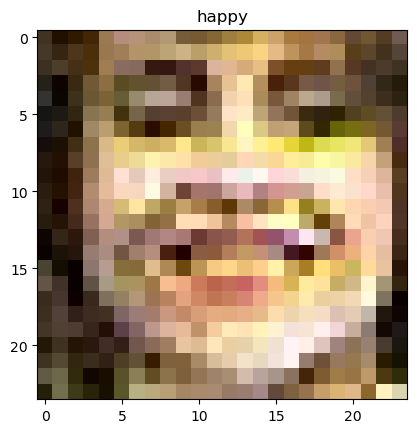

1/1 [==============================] - 0s 40ms/step


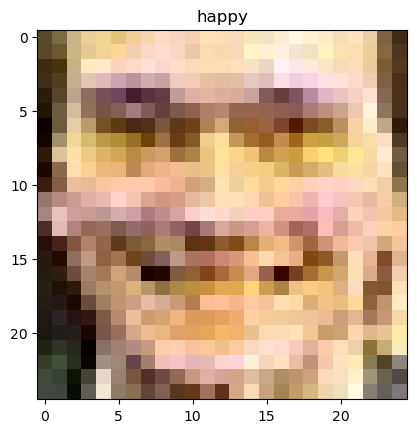

1/1 [==============================] - 0s 39ms/step


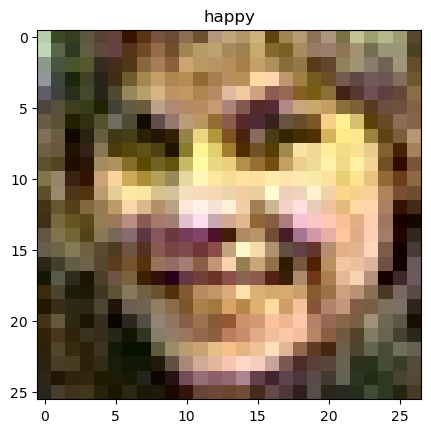

1/1 [==============================] - 0s 43ms/step


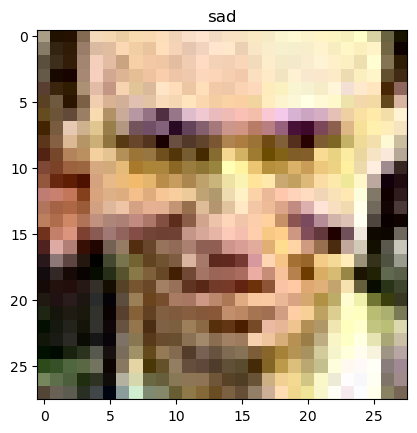

1/1 [==============================] - 0s 42ms/step


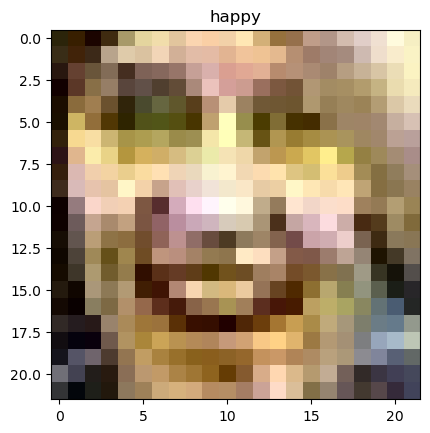

1/1 [==============================] - 0s 42ms/step


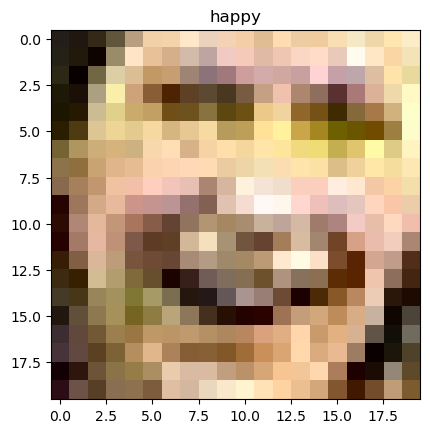

1/1 [==============================] - 0s 42ms/step


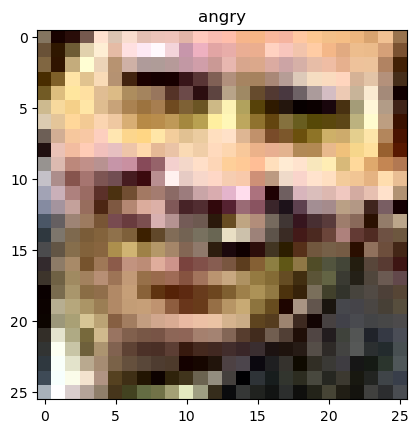

1/1 [==============================] - 0s 41ms/step


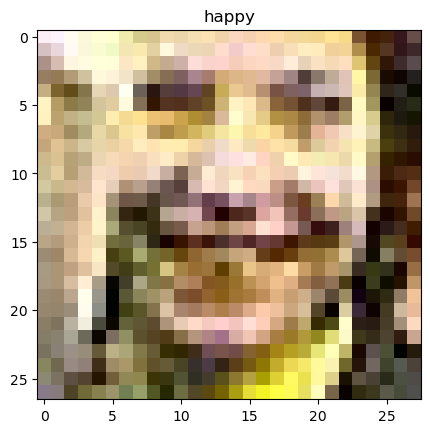

1/1 [==============================] - 0s 41ms/step


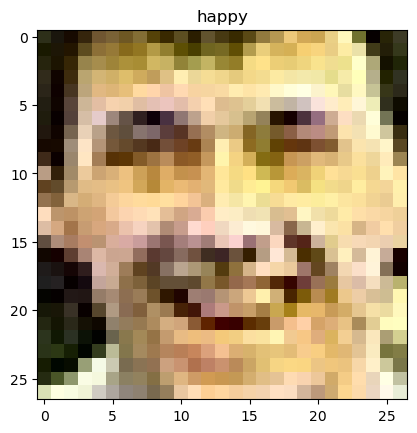

1/1 [==============================] - 0s 42ms/step


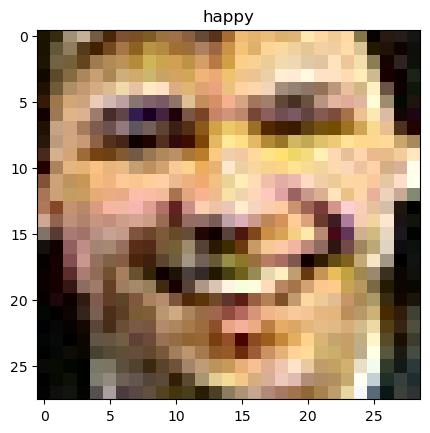

1/1 [==============================] - 0s 43ms/step


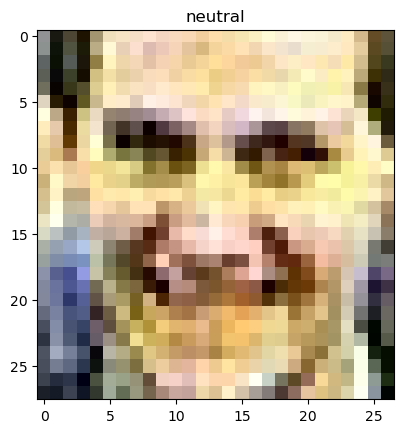

1/1 [==============================] - 0s 37ms/step


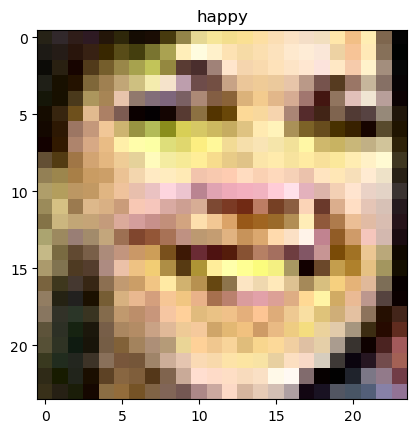

1/1 [==============================] - 0s 40ms/step


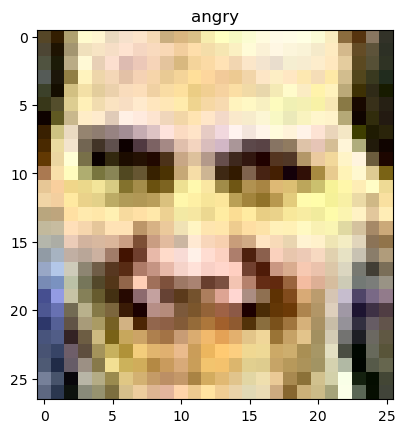

1/1 [==============================] - 0s 43ms/step


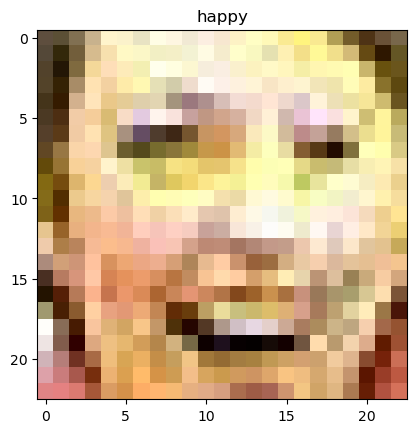

1/1 [==============================] - 0s 42ms/step


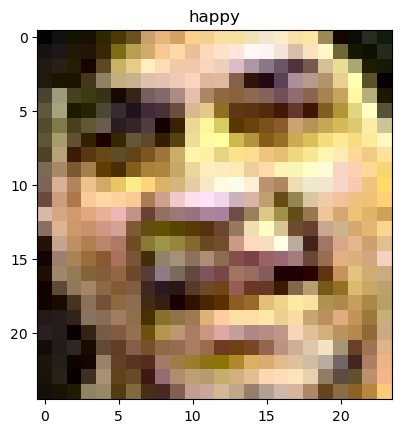

1/1 [==============================] - 0s 41ms/step


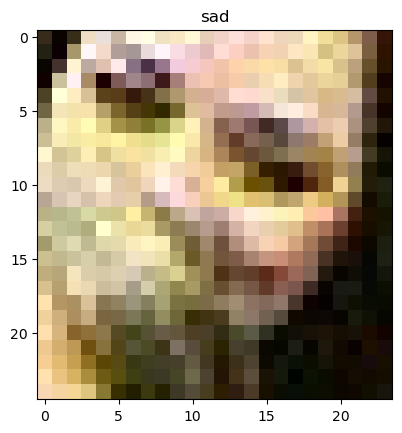

1/1 [==============================] - 0s 38ms/step


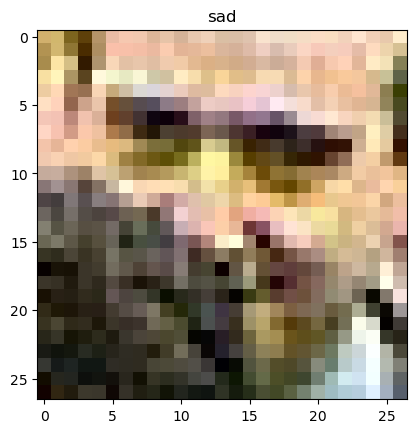

1/1 [==============================] - 0s 41ms/step


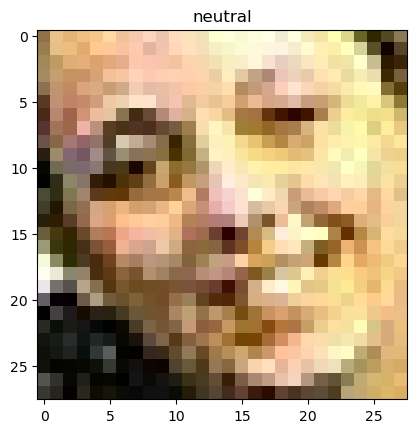

1/1 [==============================] - 0s 43ms/step


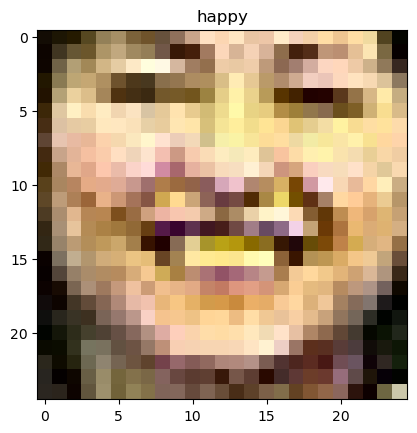

1/1 [==============================] - 0s 42ms/step


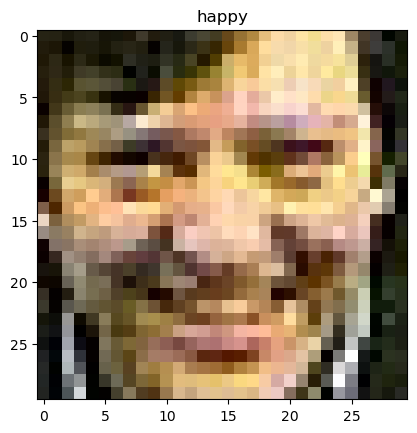

1/1 [==============================] - 0s 42ms/step


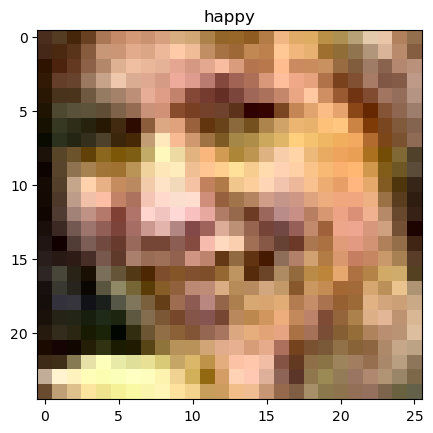

1/1 [==============================] - 0s 43ms/step


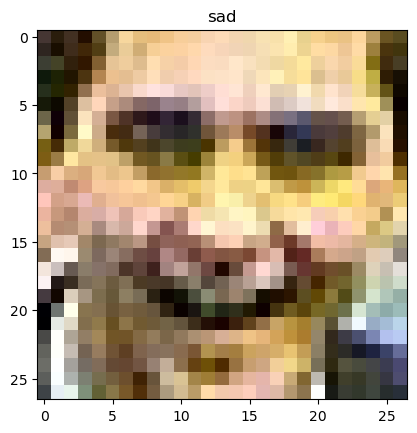

1/1 [==============================] - 0s 40ms/step


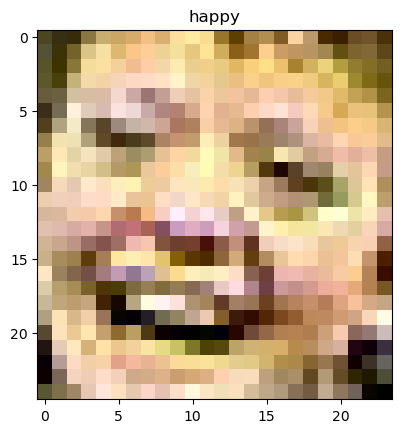

1/1 [==============================] - 0s 37ms/step


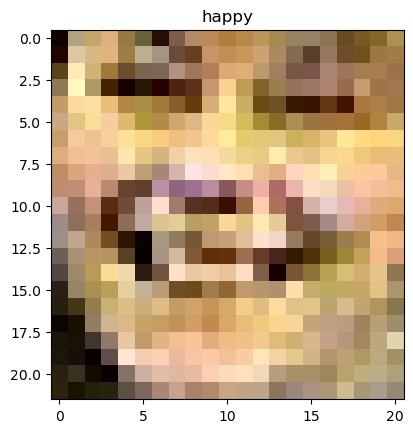

1/1 [==============================] - 0s 45ms/step


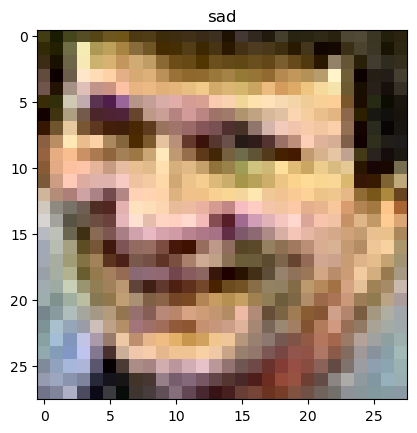

1/1 [==============================] - 0s 42ms/step


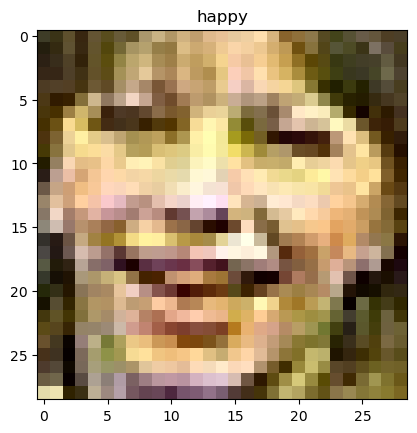

1/1 [==============================] - 0s 41ms/step


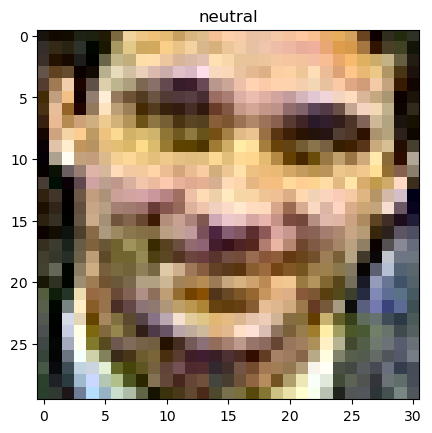

1/1 [==============================] - 0s 42ms/step


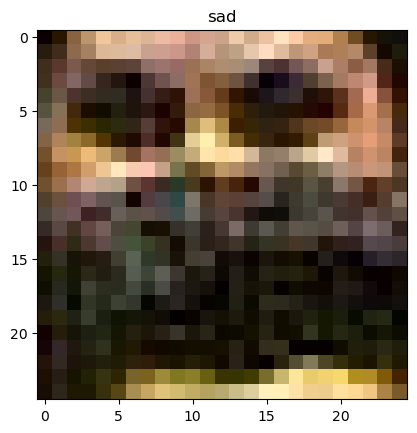

1/1 [==============================] - 0s 43ms/step


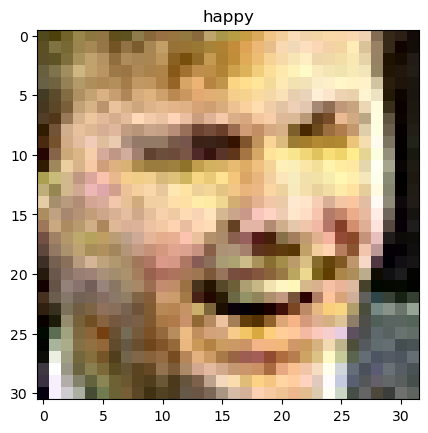

1/1 [==============================] - 0s 42ms/step


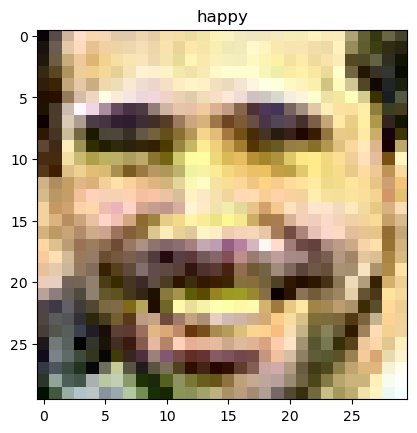

1/1 [==============================] - 0s 43ms/step


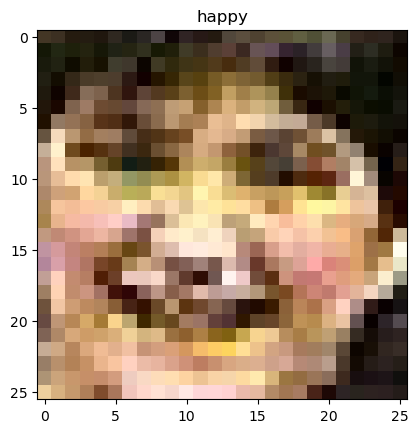

1/1 [==============================] - 0s 44ms/step


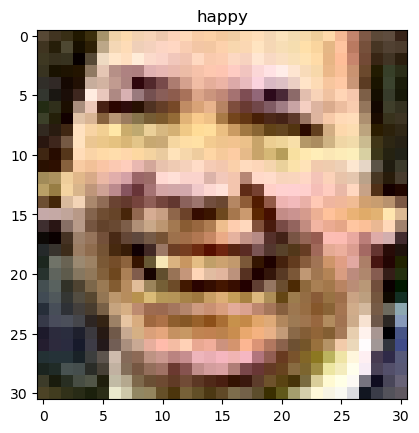

1/1 [==============================] - 0s 43ms/step


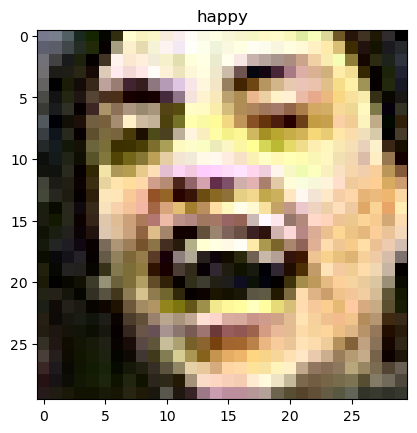

1/1 [==============================] - 0s 46ms/step


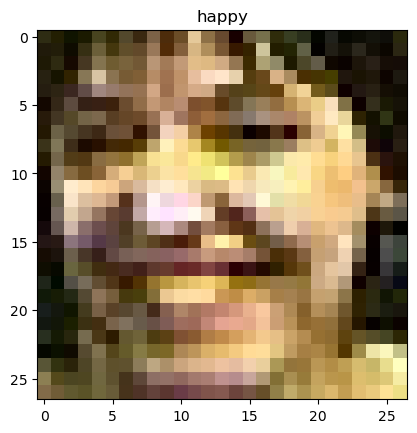

1/1 [==============================] - 0s 50ms/step


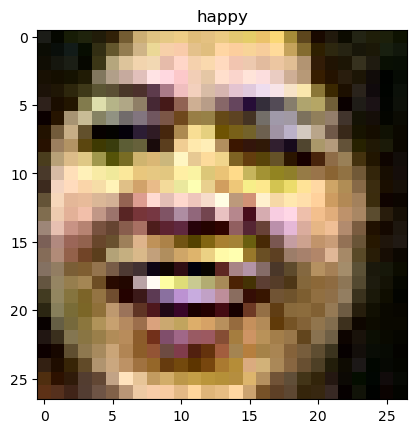

1/1 [==============================] - 0s 43ms/step


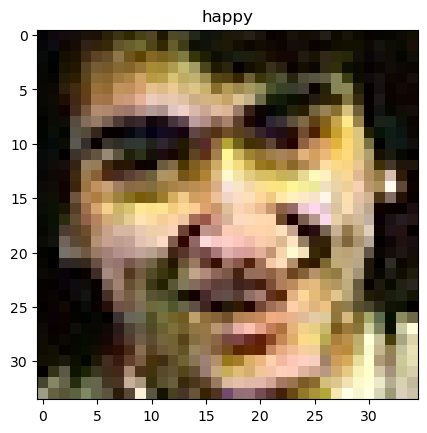

1/1 [==============================] - 0s 43ms/step


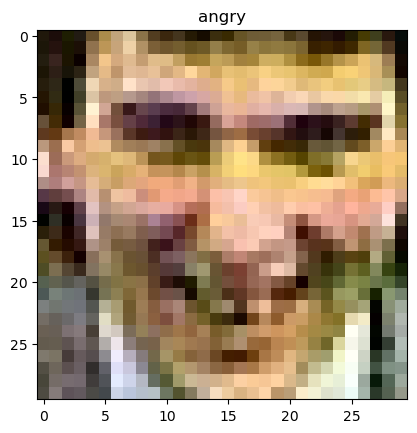

1/1 [==============================] - 0s 42ms/step


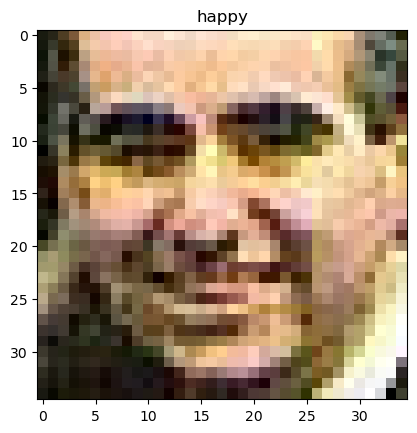

1/1 [==============================] - 0s 49ms/step


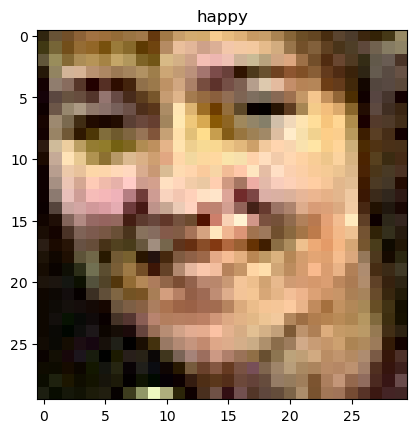

1/1 [==============================] - 0s 45ms/step


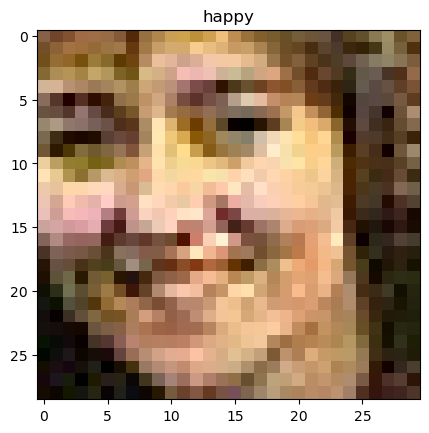

1/1 [==============================] - 0s 42ms/step


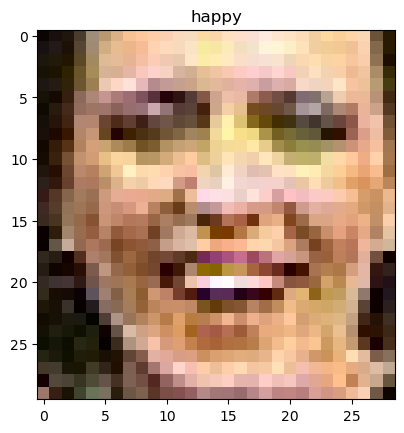

1/1 [==============================] - 0s 41ms/step


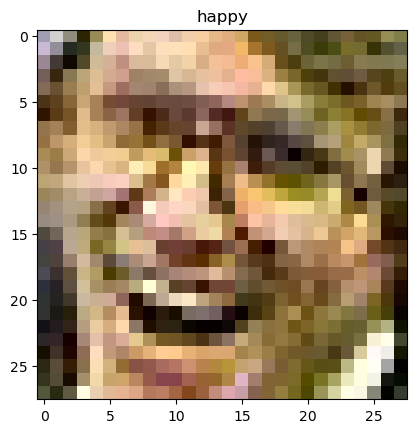

1/1 [==============================] - 0s 38ms/step


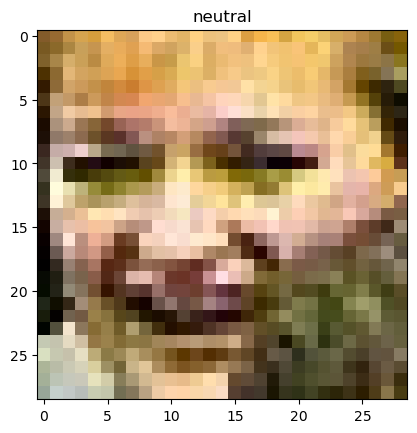

1/1 [==============================] - 0s 37ms/step


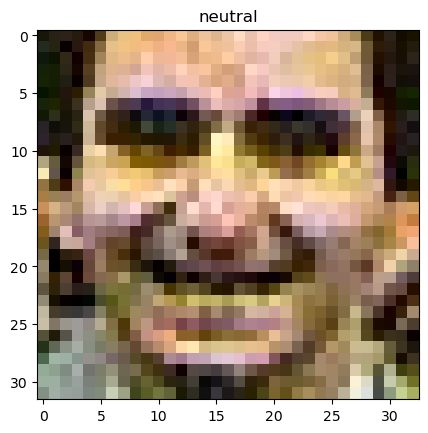

1/1 [==============================] - 0s 39ms/step


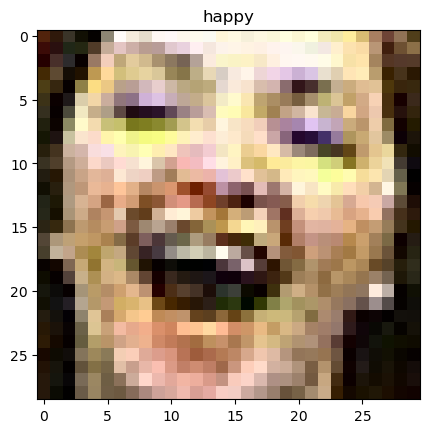

1/1 [==============================] - 0s 44ms/step


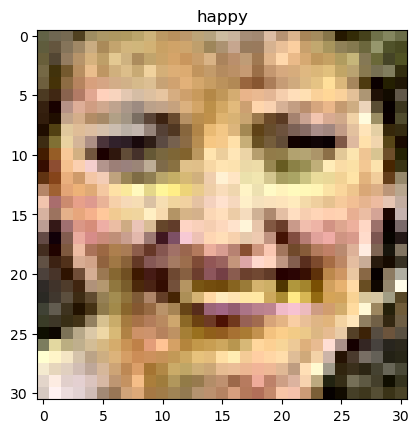

1/1 [==============================] - 0s 42ms/step


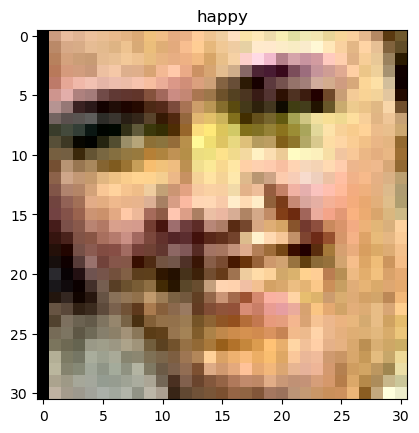

1/1 [==============================] - 0s 43ms/step


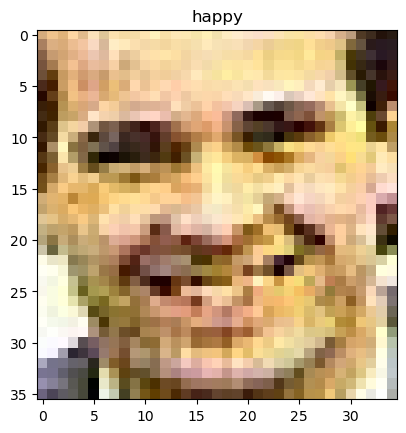

1/1 [==============================] - 0s 38ms/step


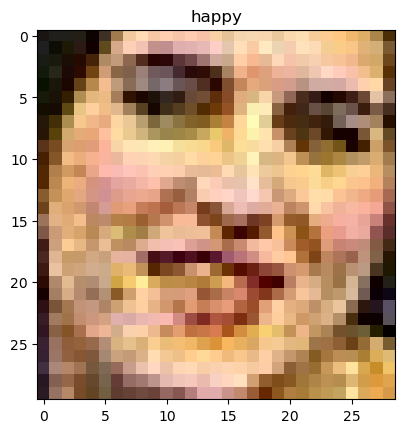

1/1 [==============================] - 0s 38ms/step


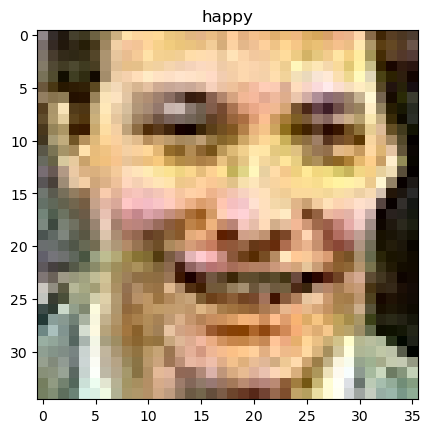

1/1 [==============================] - 0s 36ms/step


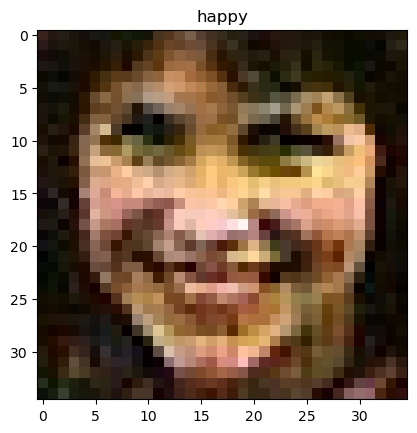

1/1 [==============================] - 0s 37ms/step


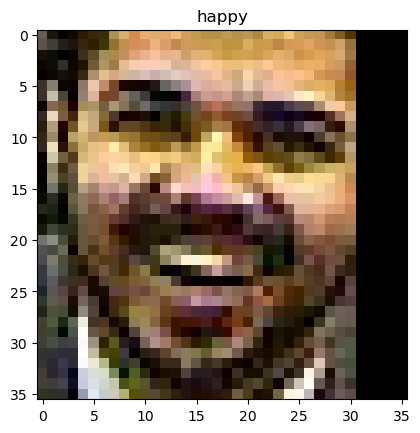

1/1 [==============================] - 0s 37ms/step


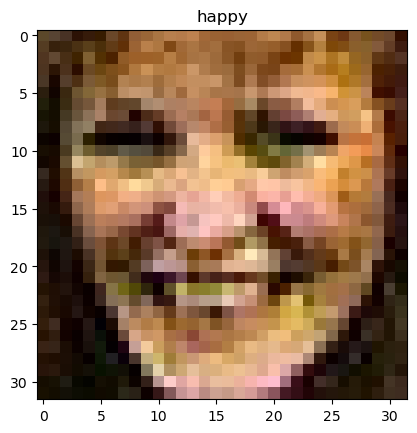

1/1 [==============================] - 0s 37ms/step


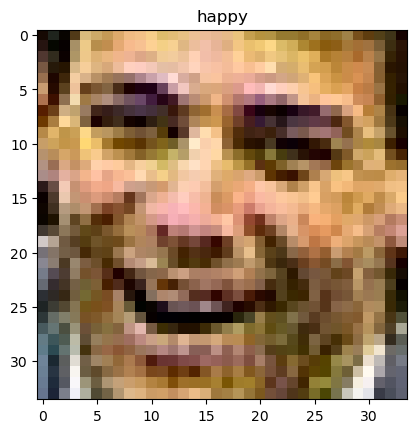

1/1 [==============================] - 0s 37ms/step


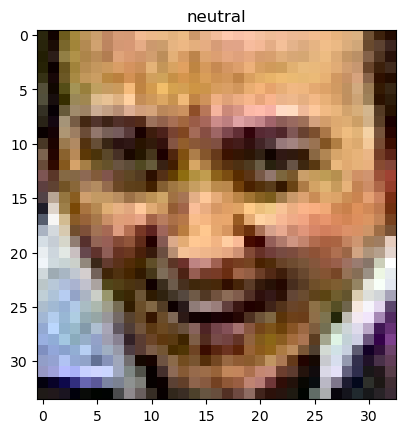

1/1 [==============================] - 0s 38ms/step


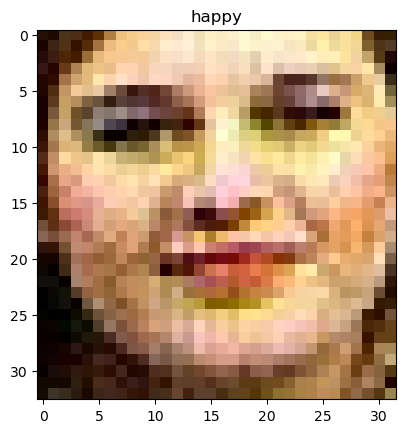

In [13]:
print(len(faces))
labels = {}
for i in range(len(faces)):
    imm = im.copy(save_trace=False).zoom(faces[i], save_trace=False)
    x = np.argmax(m2.detect_expression(imm) , axis = 1)[0]
    if m2.output_labels[x] not in labels:
        labels[m2.output_labels[x]] = 1
    else:
        labels[m2.output_labels[x]] += 1

    imm.show(desc=m2.output_labels[x])



In [12]:
labels

{'neutral': 10, 'happy': 48, 'sad': 11, 'angry': 3}

85


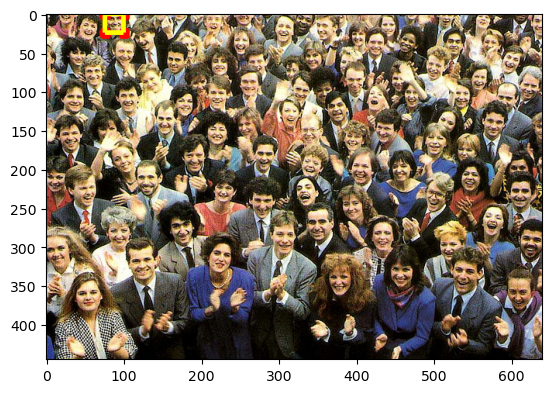

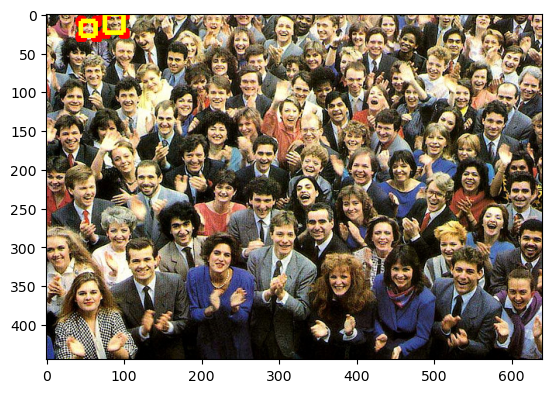

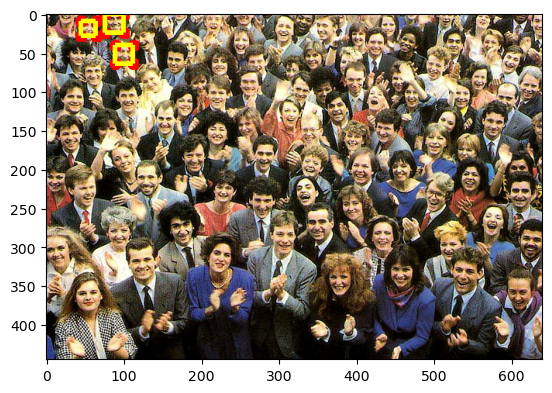

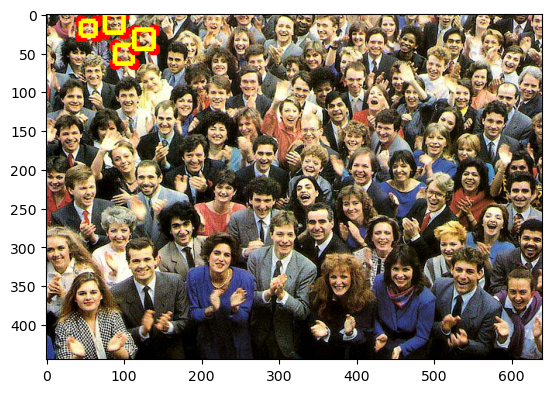

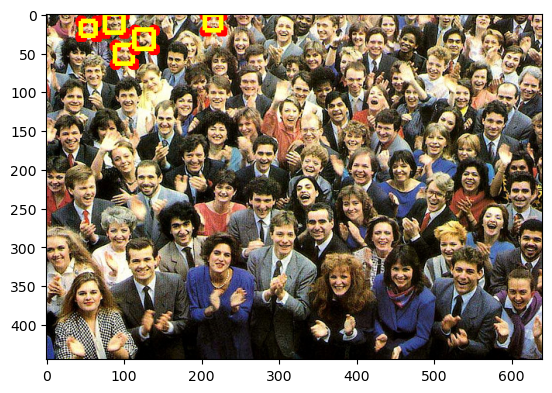

...

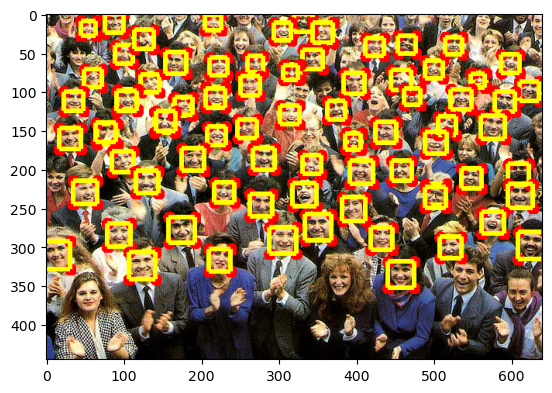

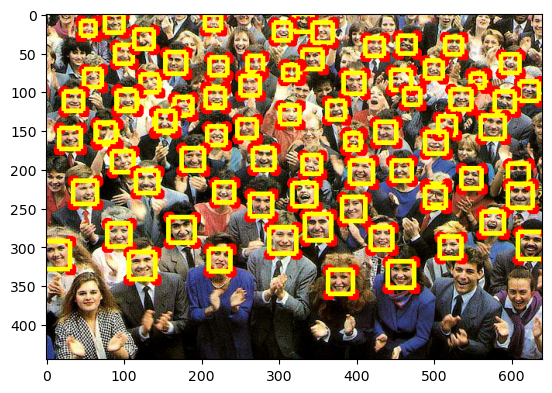

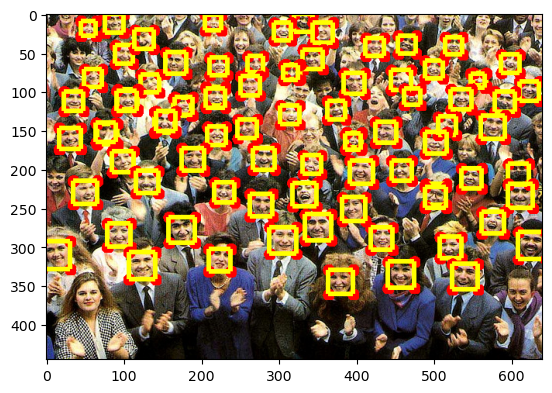

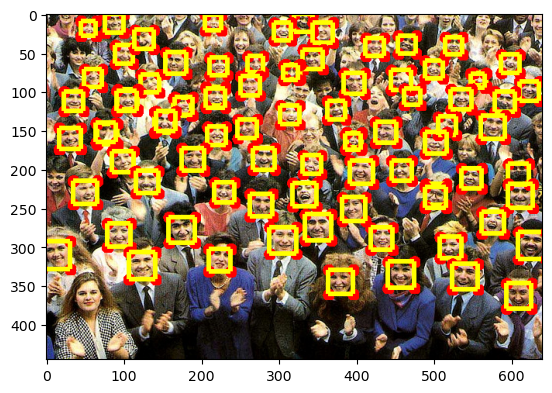

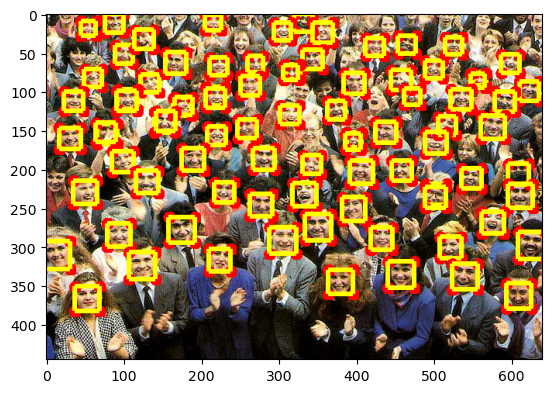

In [4]:
print(len(faces))
for i in range(len(faces)):
    im = im+faces[i]
    im.show()

In [21]:
from landpy import ImageLand
a = ImageLand()
type(a)== ImageLand

True

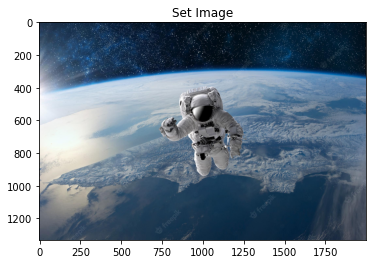

1
1


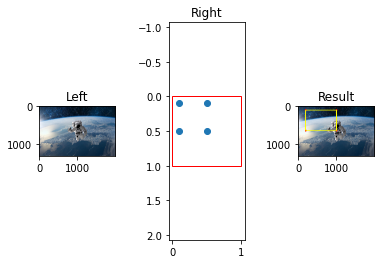

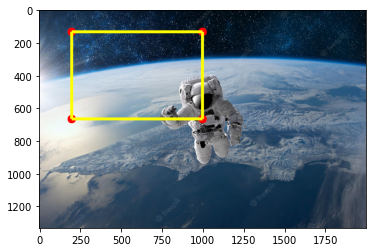

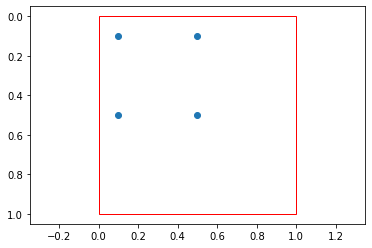

In [2]:
from landpy import ImageLand, MarksLand, SquareMarks, Debugger
debugger = Debugger(debug=True, textual_debug=False, visual_debug=True, categories=[])

(ImageLand('test.jpg', debugger=debugger)+SquareMarks(0.1,0.5,0.1,0.5)).show()
SquareMarks(0.1,0.5,0.1,0.5).show()

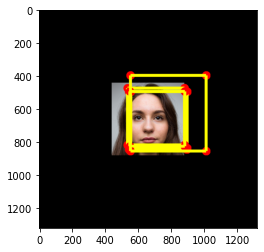

In [6]:
from landpy import ImageLand, Debugger, HeatLand, Filter, SquareMarks
from landpy.inference import load_tflite, inference_by_tflite, InferenceType
from files.blazeface_decoder import decode_boxes
import numpy as np

debugger = Debugger(debug=False, textual_debug=False, visual_debug=True, categories=[])

image = ImageLand('files/test.jpg', debugger=debugger)

w, h = image._flow_data.shape[1], image._flow_data.shape[0]

ratio1 = image._flow_data.shape[0]/image._flow_data.shape[1]
ratio2 = image._flow_data.shape[1]/image._flow_data.shape[0]
ratio3 = image._flow_data.shape[1]/(image._flow_data.shape[0]+image._flow_data.shape[1])
ratio4 = image._flow_data.shape[0]/(image._flow_data.shape[0]+image._flow_data.shape[1])
image.zoom(-1)
image.zoom(SquareMarks((-1/2)*(w/h), 1+(1/2)*(w/h), (-1/2)*(h/w), 1+(1/2)*(h/w)))

image.make_checkpoint()

image = image.reshape([128,128])
model = load_tflite('files/blazeface.tflite', debugger=debugger)
input_type = InferenceType([1,128,128,3], np.float32, does_divide=True)
output = inference_by_tflite(model, image, input_type, debugger=debugger)

all_points = decode_boxes(output[0], np.load('files/anchors.npy'))

#best_indice = np.argmax(output[1])

best_indices = np.argsort(output[1].flatten())[::-1][:5]
image.undo()
image.retrace()
for best_indice in best_indices:
    face_points = np.array(all_points[0][best_indice][0:4]) #MinX, MinY, MaxX, MaxY in (0,1)
    
    sm = SquareMarks(face_points[1], face_points[3], face_points[0], face_points[2], debugger=debugger)
    sm = sm.zoom(SquareMarks((w/(w+h))/2, 1-(w/(w+h))/2, (h/(w+h))/2, 1-(h/(w+h)/2)))
    image = (image+sm)
image.show()


In [10]:
min((1,2),(3,1))

(1, 2)

In [5]:
sm.minX(),sm.maxX(), sm.minY(),sm.maxY(), sm._flow_data

(0.3746025,
 0.99363935,
 -0.7325139,
 -0.113479465,
 array([[ 0.3746025 , -0.7325139 ],
        [ 0.3746025 , -0.11347947],
        [ 0.99363935, -0.11347947],
        [ 0.99363935, -0.7325139 ]], dtype=float32))

In [46]:
min(slice(2,3), slice(1,2))

slice(1, 2, None)

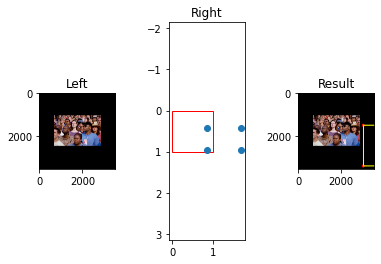

In [4]:
image+sm

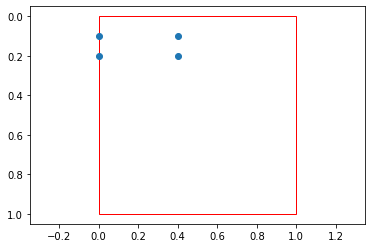

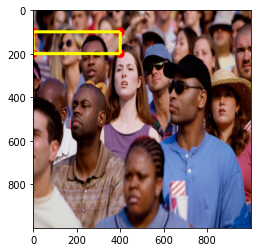

1.2000000000000002


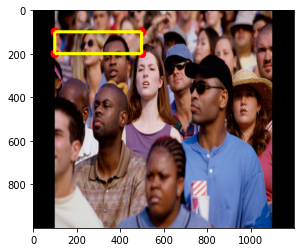

In [2]:
from landpy import ImageLand, Debugger, HeatLand, Filter, SquareMarks

debugger = Debugger(debug=False, textual_debug=False, visual_debug=True, categories=[])

image = ImageLand('files/crowd.jpg', debugger=debugger)

sm = SquareMarks(0.1,0.2,0,0.4, debugger=debugger)
sm.show()
sq = SquareMarks(0,1.0,-0.1,1.1)
(image+sm).show()
smz = sm.copy()
(image.zoom(sq)+sm.zoom(sq)).show()

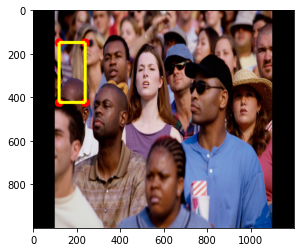

In [2]:
(image+sm).show()

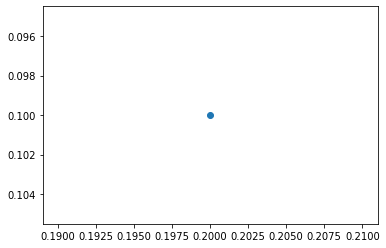

In [9]:
import matplotlib.pylab as plt
if not plt.gca().yaxis_inverted():
    plt.gca().invert_yaxis()
    
plt.scatter([0.2],[0.1])

In [6]:
sm._flow_data


array([[0.1  , 0.15 ],
       [0.1  , 0.425],
       [0.2  , 0.425],
       [0.2  , 0.15 ]])

In [4]:
image._flow_data.shape

(1000, 1200, 3)

In [6]:
sm._flow_data

array([[0.1  , 0.15 ],
       [0.1  , 0.425],
       [0.2  , 0.425],
       [0.2  , 0.15 ]])

In [2]:
print(sm._flow_data, smz._flow_data)

[[0.1        0.08333333]
 [0.1        0.41666667]
 [0.2        0.41666667]
 [0.2        0.08333333]] [[0.1 0. ]
 [0.1 0.4]
 [0.2 0.4]
 [0.2 0. ]]


1


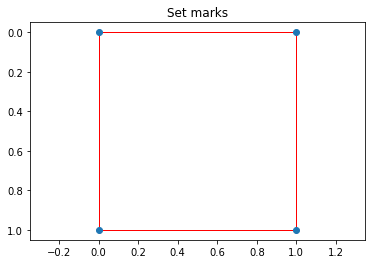

1


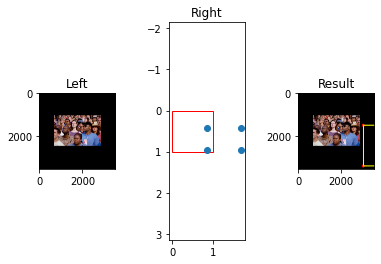

In [14]:
sm._flow_data, sm.minX, sm.maxX


(array([[0.6379189, 0.4142632],
        [0.6379189, 0.6785233],
        [0.9701145, 0.6785233],
        [0.9701145, 0.4142632]], dtype=float32),
 0.5548559,
 0.6869834)

slice(571, 757, None) slice(1173, 1191, None)


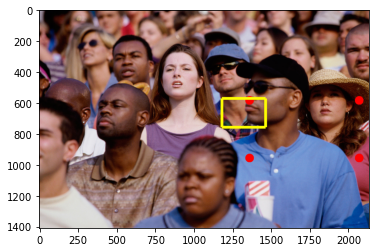

In [11]:
(ImageLand('files/crowd.jpg')+sm).show()

In [4]:
sm._flow_data

array([[0.6379189, 0.4142632],
       [0.6379189, 0.6785233],
       [0.9701145, 0.6785233],
       [0.9701145, 0.4142632]], dtype=float32)

slice(583, 955, None) slice(1351, 1369, None)


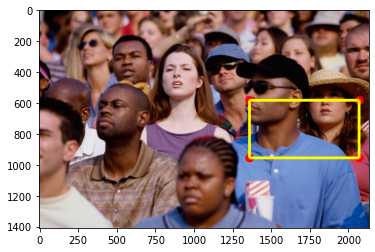

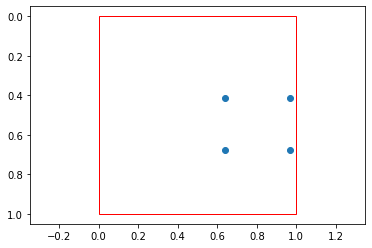

In [2]:
from landpy import SquareMarks, ImageLand
image = ImageLand('files/crowd.jpg')
sq = SquareMarks(0.6379189,0.9701145,0.4142632,0.6785233)

(image+sq).show()
sq.show()

In [7]:
face_points[[0,1]]

SyntaxError: can't use starred expression here (Temp/ipykernel_41592/2582388711.py, line 1)

 Debugger init ended time = 41.8547


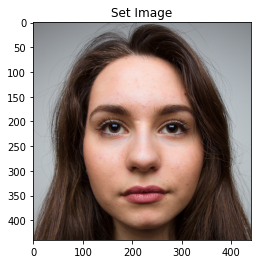

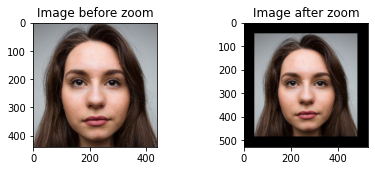

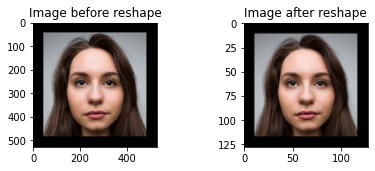

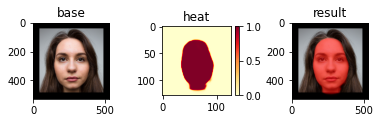

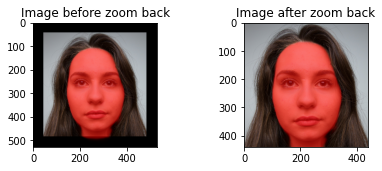

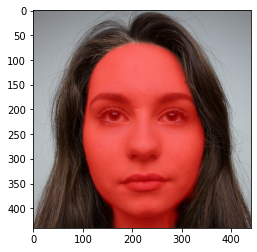

In [2]:
from landpy import ImageLand, Debugger, HeatLand, Filter, SquareMarks
from landpy.inference import load_tflite, inference_by_tflite, InferenceType
import numpy as np

debugger = Debugger(debug=True, textual_debug=False, visual_debug=True, categories=[])

image = ImageLand('files/test.jpg', debugger=debugger).zoom(-0.1)
image.make_checkpoint()

image = image.reshape([128,128])
model = load_tflite('files/face_segm.tflite', debugger=debugger)
input_type = InferenceType([1,128,128,3], np.float32, does_divide=True)
output = inference_by_tflite(model, image, input_type, debugger=debugger)
heat = HeatLand(output.reshape([128,128]))

image.undo()
image.implant_filter(Filter('#ff0000', ratio=0.5), heat)
image.retrace()

image.show()

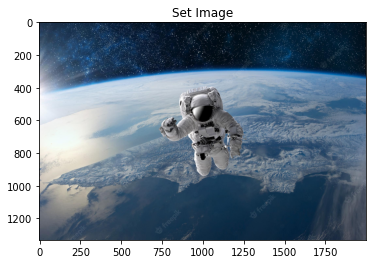

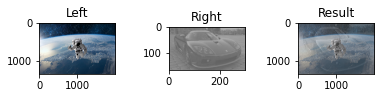

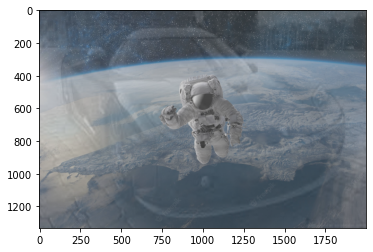

In [3]:
from landpy import ImageLand, Debugger
debugger = Debugger(debug=True, textual_debug=False, visual_debug=True, categories=[])

(ImageLand('test.jpg', debugger=debugger)+ImageLand('test2.jpg')).show()

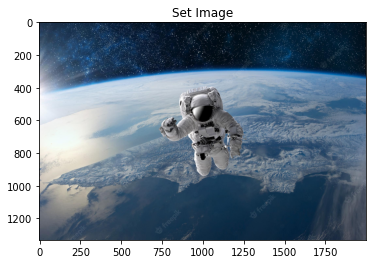

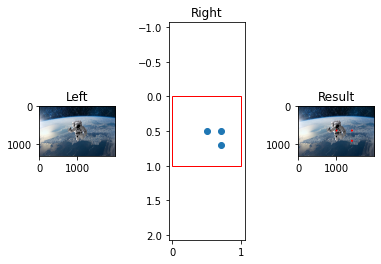

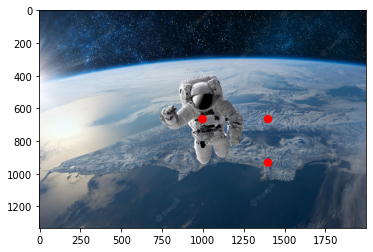

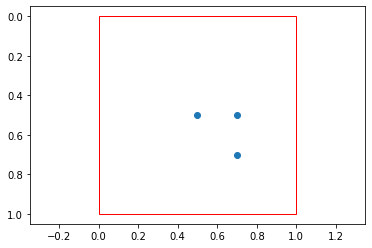

In [1]:
from landpy import ImageLand, MarksLand, Debugger
debugger = Debugger(debug=True, textual_debug=False, visual_debug=True, categories=[])

(ImageLand('test.jpg', debugger=debugger)+MarksLand([[0.5,0.5],[0.7,0.7], [0.7,0.5]])).show()
MarksLand([[0.5,0.5],[0.7,0.7], [0.7,0.5]]).show()

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
np.ogrid[1:4,4:8]

[array([[1],
        [2],
        [3]]),
 array([[4, 5, 6, 7]])]

 Debugger init started 
 Debugger init ended time = 44.8584
	 Setting image started 


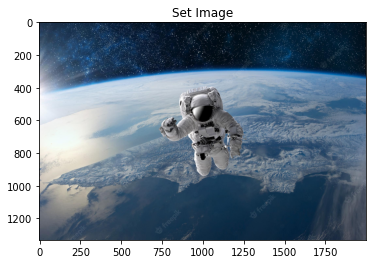

		 Setting flow_data started 
		 Setting flow_data ended time = 0.0000
	 Setting image ended time = 0.4129
	 Adding an image to another object (image or heat or marks) started 
		 Left saved! time = 0.0000
		 Right saved! time = 0.0050
		 Adding an image to another object (image or heat or marks) started 
			 Copying image started 
				 Copying Land started 
					 Copying the whole trace started 
					 Copying the whole trace ended time = 0.0031
				 Copying Land ended time = 0.0031
			 Copying image ended time = 0.0031
			 Heat and Image weren't in the same size so heat is going to reshape! time = 0.0031
		 Adding an image to another object (image or heat or marks) ended time = 0.2911
		 Result saved! time = 0.2961


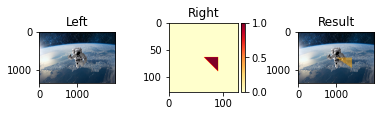

	 Adding an image to another object (image or heat or marks) ended time = 0.9400
	 Showing the image started 


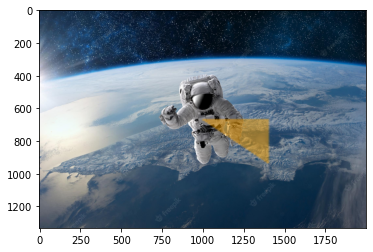

	 Showing the image ended time = 0.4929


In [3]:
from landpy import ImageLand, MarksLand, Debugger
debugger = Debugger(debug=True, textual_debug=True, visual_debug=True, categories=[])

(ImageLand('test.jpg', debugger=debugger)+MarksLand([[0.5,0.5],[0.7,0.7], [0.7,0.5]]).to_heat()).show()

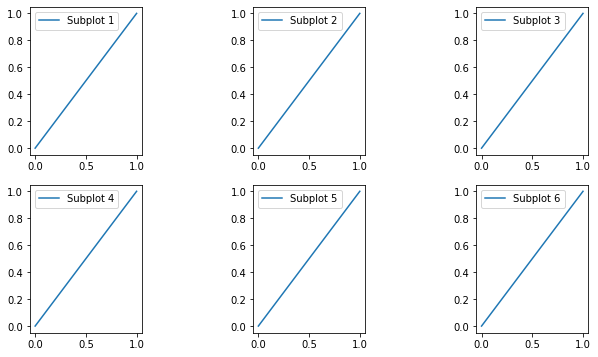

In [6]:
import matplotlib.pyplot as plt

# Define the dimensions of the subplot grid
dim = (2, 3)  # 2 rows, 3 columns

# Create a figure and subplots
fig = plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

for i in range(dim[0] * dim[1]):
    ax = fig.add_subplot(dim[0], dim[1], i+1)
    ax.plot([0, 1], [0, 1], label=f'Subplot {i+1}')
    ax.legend()

# Adjust spacing between subplots
plt.subplots_adjust(wspace=1)  # Adjust the hspace value as needed

plt.show()


In [3]:
import numpy as np
from PIL import Image

# Open the images using Pillow (PIL)
image1 = Image.open('test.jpg')
image2 = Image.open('test2.jpg')

# Convert the images to NumPy arrays
array1 = np.array(image1)
array2 = np.array(image2)

# Blend the images using NumPy
alpha = 0.5  # Adjust transparency (0: fully transparent, 1: fully opaque)
overlay = np.uint8(array1 * alpha + array2 * (1 - alpha))

# Create a new PIL Image from the blended array
result_image = Image.fromarray(overlay)

# Display the result
result_image.show()


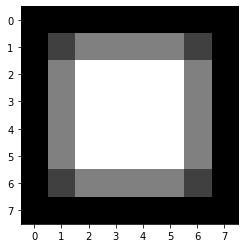

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Create a simple grayscale image (8x8 pixels)
image_data = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 64, 128, 128, 128, 128, 64, 0],
    [0, 128, 255, 255, 255, 255, 128, 0],
    [0, 128, 255, 255, 255, 255, 128, 0],
    [0, 128, 255, 255, 255, 255, 128, 0],
    [0, 128, 255, 255, 255, 255, 128, 0],
    [0, 64, 128, 128, 128, 128, 64, 0],
    [0, 0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)


# Plot the image
plt.imshow(image_data, cmap='gray')

# Set labels for pixel axes
plt.xticks(np.arange(len(image_data[0])), np.arange(len(image_data[0])))
plt.yticks(np.arange(len(image_data)), np.arange(len(image_data)))


# Display the plot
plt.show()


In [7]:
from PIL import Image
import numpy as np
np.array(Image.open('test.jpg')).reshape([100,-1]).astype(float)

array([[35., 53., 77., ...,  6., 23., 41.],
       [ 6., 23., 41., ...,  0.,  3., 12.],
       [ 0., 12., 20., ...,  1., 22., 39.],
       ...,
       [59., 74., 93., ..., 22., 50., 74.],
       [23., 51., 75., ..., 12., 40., 64.],
       [12., 40., 64., ..., 69., 75., 89.]])

In [5]:
a = 'None'
type(a) is str

True

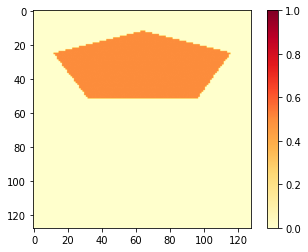

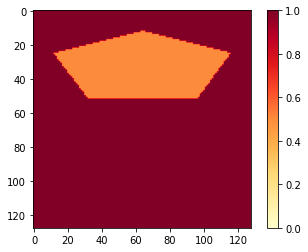

In [3]:
from landpy import MarksLand, Debugger
import numpy as np

heat = MarksLand(np.array([(0.1, 0.2), (0.5, 0.1), (0.9, 0.2),
                 (0.75, 0.4), (0.25, 0.4)])).to_heat(fill_heat=0.5)
heat.show()
(-heat).show()

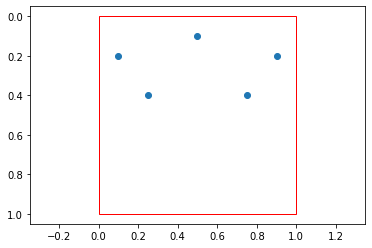

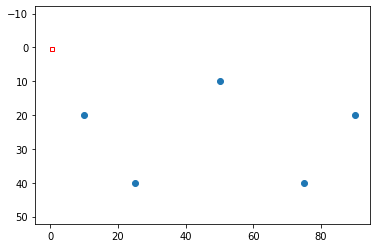

In [2]:
from landpy import MarksLand, Debugger
import numpy as np
debugger = Debugger(debug=True, textual_debug=True, visual_debug=False, categories=['HeatLand'])

marks = np.array([(0.1,0.2), (0.5,0.1), (0.9,0.2), (0.75,0.4), (0.25,0.4)])
land = MarksLand(marks, debugger=debugger)
land.show()
land.reshape((1,1),(100,100))
land.show()

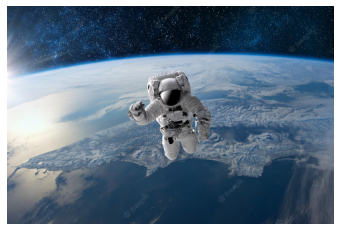

[[  0.   0.]
 [  0. 149.]
 [ 84. 149.]
 [ 84.   0.]] [[   0.    0.]
 [   0. 1000.]
 [ 665. 1000.]
 [ 665.    0.]]
[[  0.   0.]
 [  0. 149.]
 [ 84. 149.]
 [ 84.   0.]] [[   0.    0.]
 [   0. 1000.]
 [ 665. 1000.]
 [ 665.    0.]]


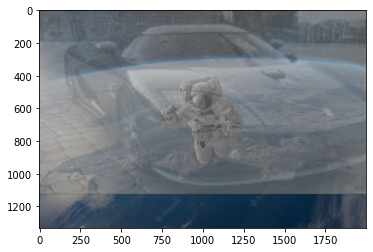

In [5]:
from PIL import Image
import importlib
import landpy
from landpy import ImageLand, Debugger, Filter, HeatLand, MarksLand, SquareMarks
import numpy as np
import matplotlib.pyplot as plt

image = np.array(Image.open('test.jpg'))
land = ImageLand(image)
land.show()
image2 = np.array(Image.open('test2.jpg'))
plt.imshow(image2)
plt.imshow(land.implant_image(image2, SquareMarks(0,0.5,0,0.5),  SquareMarks(0,0.5,0,0.5), ratio=0.7)._flow_data)

In [7]:
import numpy as np
np.array([1,2])/np.array([10,100])

array([0.1 , 0.02])

In [2]:
image2

array([[[ 97,  97,  97],
        [103, 103, 103],
        [110, 110, 110],
        ...,
        [171, 171, 171],
        [176, 176, 176],
        [182, 182, 182]],

       [[104, 104, 104],
        [106, 106, 106],
        [106, 106, 106],
        ...,
        [164, 164, 164],
        [170, 170, 170],
        [176, 176, 176]],

       [[108, 108, 108],
        [114, 114, 114],
        [120, 120, 120],
        ...,
        [160, 160, 160],
        [167, 167, 167],
        [174, 174, 174]],

       ...,

       [[145, 145, 145],
        [144, 144, 144],
        [142, 142, 142],
        ...,
        [134, 134, 134],
        [134, 134, 134],
        [135, 135, 135]],

       [[146, 146, 146],
        [144, 144, 144],
        [142, 142, 142],
        ...,
        [132, 132, 132],
        [136, 136, 136],
        [142, 142, 142]],

       [[142, 142, 142],
        [140, 140, 140],
        [137, 137, 137],
        ...,
        [109, 109, 109],
        [115, 115, 115],
        [125, 125, 125]]

In [2]:
import numpy as np
from landpy import SquareMarks, MarksLand, QuadMarks, Debugger

np.array([[1,2],[3,4],[5,6]])*np.array([10,100])

SquareMarks(debugger=Debugger(debug=True, textual_debug=True))._flow_data*np.array([10,100])

 Debugger init started 
	 Setting marks started 
		 Converting to (n,2) matrix started 
		 Converting to (n,2) matrix ended time = 0.0000
		 Setting flow_data started 
		 Setting flow_data ended time = 0.0000
	 Setting marks ended time = 0.0010
	 Setting QuadMarks started 
		 Setting marks started 
			 Converting to (n,2) matrix started 
			 Converting to (n,2) matrix ended time = 0.0000
			 Setting flow_data started 
			 Setting flow_data ended time = 0.0000
		 Setting marks ended time = 0.0000
	 Setting QuadMarks ended time = 0.0000
	 Setting SquareMarks started 
		 Setting marks started 
			 Converting to (n,2) matrix started 
			 Converting to (n,2) matrix ended time = 0.0000
			 Setting flow_data started 
			 Setting flow_data ended time = 0.0000
		 Setting marks ended time = 0.0000
	 Setting SquareMarks ended time = 0.0000
 Debugger init ended time = 0.0010


array([[  0,   0],
       [  0, 100],
       [ 10,   0],
       [ 10, 100]])

In [7]:
dir(Type['MyClass'])

['__args__',
 '__call__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__instancecheck__',
 '__le__',
 '__lt__',
 '__module__',
 '__mro_entries__',
 '__ne__',
 '__new__',
 '__origin__',
 '__parameters__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slots__',
 '__str__',
 '__subclasscheck__',
 '__subclasshook__',
 '__weakref__',
 '_inst',
 '_name',
 'copy_with']

In [20]:
def type_check_decorator(func):
    def wrapper(*args, **kwargs):
        func_args = func.__code__.co_varnames[:func.__code__.co_argcount]
        for arg_name, arg_value in zip(func_args, args):
            arg_type = func.__annotations__.get(arg_name)
            if arg_type and not isinstance(arg_value, arg_type):
                raise TypeError(f"Argument '{arg_name}' should be of type {arg_type.__name__}")
        result = func(*args, **kwargs)
        return result
    return wrapper

# Example function that uses the decorator
@type_check_decorator
def add_numbers(a: int, b: Type['MyClass']) -> int:
    return a + b

try:
    result = add_numbers(10, 20)
    print("Result:", result)  # Output: Result: 30

    add_numbers(10, "20")  # This will raise a TypeError
except TypeError as e:
    print("TypeError:", e)  # Output: TypeError: Argument 'b' should be of type int


TypeError: Subscripted generics cannot be used with class and instance checks


In [11]:
Type['MyClass']

typing.Type[ForwardRef('MyClass')]

In [7]:
import inspect
import time
from abc import ABC, abstractmethod
from typing import Callable, List, Tuple, Dict, Literal, Any, Iterable
from landpy import ImageLand, Debugger, QuadMarks, SquareMarks
from PIL import Image
import numpy as np
import time
import matplotlib.pylab as plt
import cv2

In [1]:
from PIL import Image
import importlib
import landpy
from landpy import ImageLand, Debugger, Filter, HeatLand, MarksLand
import numpy as np
import matplotlib.pyplot as plt


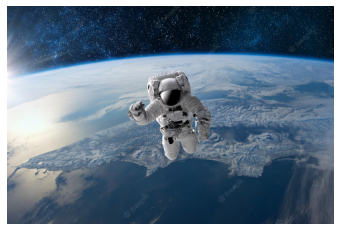

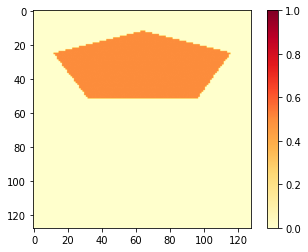

 Debugger init started 
	 implanting filter in image started 
		 Heat and Image weren't in the same size so heat is going to reshape! time = 0.0000
		 Image before implant saved! time = 0.0200
		 Image after implant saved! time = 0.1380


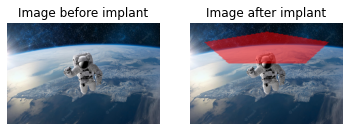

	 implanting filter in image ended time = 0.6051


In [1]:
from PIL import Image
import importlib
import landpy
from landpy import ImageLand, Debugger, Filter, HeatLand, MarksLand
import numpy as np
import matplotlib.pyplot as plt

heat = MarksLand(np.array([(0.1, 0.2), (0.5, 0.1), (0.9, 0.2),
                 (0.75, 0.4), (0.25, 0.4)])).to_heat(fill_heat=0.5)
image = np.array(Image.open('test.jpg'))
land = ImageLand(image)
land.show()
heat.show()

land.set_debugger(Debugger(textual_debug=True, visual_debug=True, show_file=False, show_line=False))
land.implant_filter(Filter((255,0,0)), heat)

In [4]:
class A:
    def __init__(self, value):
        self.value = value

    def to_b(self):
        # Convert instance of A to an instance of B
        return B(self.value * 2)

class B:
    def __init__(self, value):
        self.value = value

    def to_a(self):
        # Convert instance of B to an instance of A
        return A(self.value // 2)

A(5).to_b()

In [5]:
image.shape

(1331, 2000, 3)

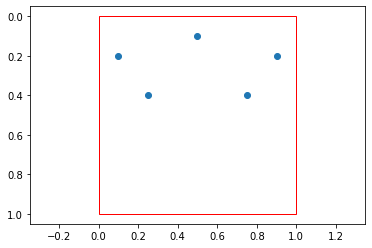

 Setting heat started 
 Setting heat ended time = 0.0000
 Rotating heat started 
	 (angle, center) = (30, (64, 64)) time = 0.0000
 Rotating heat ended time = 0.0030
 Showing the heat started 


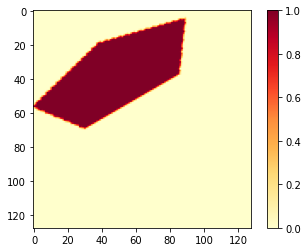

 Showing the heat ended time = 0.1034
 Reshaping heat started 
	 (w, h) = (100, 120) time = 0.0000
	 Setting heat started 
	 Setting heat ended time = 0.0000
 Reshaping heat ended time = 0.0010
(120, 100)
 Showing the heat started 


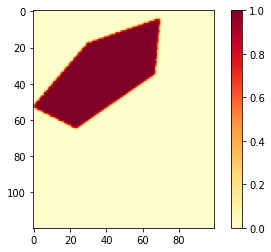

 Showing the heat ended time = 0.0950
 Reshaping back heat started 
	 (w, h) = (128, 128) time = 0.0000
 Reshaping back heat ended time = 0.0010
 Showing the heat started 


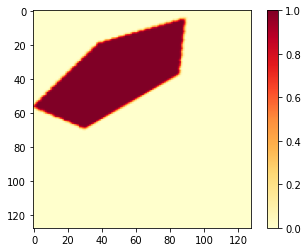

 Showing the heat ended time = 0.1010


In [3]:
from landpy import MarksLand, Debugger

import numpy as np
debugger = Debugger(debug=True, textual_debug=True, visual_debug=False, categories=['HeatLand'])
marks = np.array([(0.1,0.2), (0.5,0.1), (0.9,0.2), (0.75,0.4), (0.25,0.4)])
land1 = MarksLand(marks, debugger=debugger)
land1.show()
heat = land1.to_heat()
heat.rotate(30)
heat.show()
heat.reshape((100,120))
heat.show()
heat.retrace()
heat.show()

In [9]:
import numpy as np
from PIL import Image

def change_matrix_size(matrix, shape):
        im = Image.fromarray((matrix*255).astype('uint8'))
        im = im.resize((shape[1],shape[0]))
        im = np.array(im)/255
        return im

heat1 = heat[:]
heat2 = change_matrix_size(heat1, (100,100))
heat1.shape , heat2.shape

((128, 128), (100, 100))

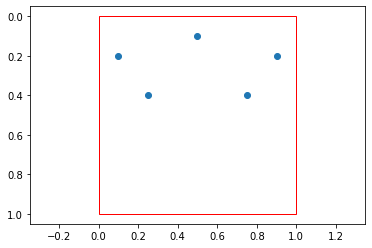

 Setting heat started 
 Setting heat ended time = 0.0000
 Showing the heat started 


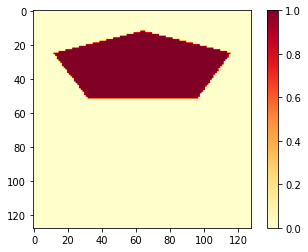

 Showing the heat ended time = 0.1572


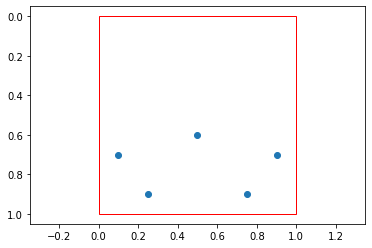

 Setting heat started 
 Setting heat ended time = 0.0000
 Showing the heat started 


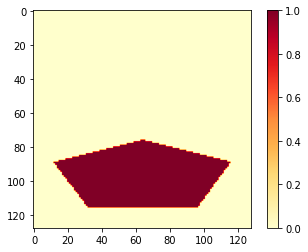

 Showing the heat ended time = 0.1363
 Setting heat started 
 Setting heat ended time = 0.0000
 Setting heat started 
 Setting heat ended time = 0.0010
 Adding two heats (maximums in each place) started 
	 Setting heat started 
	 Setting heat ended time = 0.0000
 Adding two heats (maximums in each place) ended time = 0.0000
 Showing the heat started 


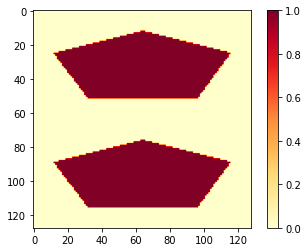

 Showing the heat ended time = 0.1560
 Setting heat started 
 Setting heat ended time = 0.0000
 Multiplying a number to a heats started 
	 Setting heat started 
	 Setting heat ended time = 0.0010
 Multiplying a number to a heats ended time = 0.0010
 Setting heat started 
 Setting heat ended time = 0.0008
 Multiplying a number to a heats started 
	 Setting heat started 
	 Setting heat ended time = 0.0000
 Multiplying a number to a heats ended time = 0.0000
 Adding two heats (maximums in each place) started 
	 Setting heat started 
	 Setting heat ended time = 0.0010
 Adding two heats (maximums in each place) ended time = 0.0010
 Showing the heat started 


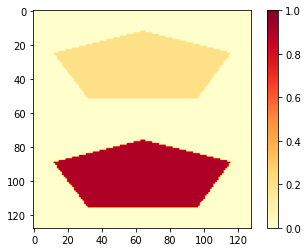

 Showing the heat ended time = 0.1790
 Setting heat started 
 Setting heat ended time = 0.0000
 Multiplying a number to a heats started 
	 Setting heat started 
	 Setting heat ended time = 0.0010
 Multiplying a number to a heats ended time = 0.0010
 Powerring a heat to a number started 
	 Setting heat started 
	 Setting heat ended time = 0.0000
 Powerring a heat to a number ended time = 0.0000
 Showing the heat started 


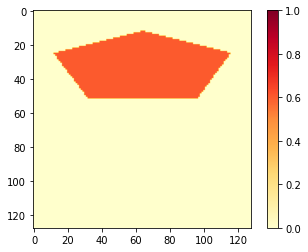

 Showing the heat ended time = 0.1525
 Setting heat started 
 Setting heat ended time = 0.0000
 Multiplying a number to a heats started 
	 Setting heat started 
	 Setting heat ended time = 0.0000
 Multiplying a number to a heats ended time = 0.0010
 Powerring a heat to a number started 
	 Setting heat started 
	 Setting heat ended time = 0.0000
 Powerring a heat to a number ended time = 0.0000
 Showing the heat started 


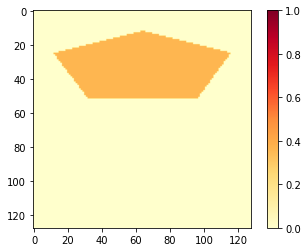

 Showing the heat ended time = 0.1321


In [8]:
#Test heat
from landpy import MarksLand, Debugger

import numpy as np
debugger = Debugger(debug=True, textual_debug=True, visual_debug=False, categories=['HeatLand'])
marks = np.array([(0.1,0.2), (0.5,0.1), (0.9,0.2), (0.75,0.4), (0.25,0.4)])
land1 = MarksLand(marks, debugger=debugger)
land1.show()
land1.to_heat().show()

marks = np.array([(0.1,0.7), (0.5,0.6), (0.9,0.7), (0.75,0.9), (0.25,0.9)])
land2 = MarksLand(marks, debugger=debugger)
land2.show()
land2.to_heat().show()

(land1.to_heat()+land2.to_heat()).show()
(0.2*land1.to_heat()+0.9*land2.to_heat()).show()
((0.6*land1.to_heat())**1).show()
((0.6*land1.to_heat())**2).show()

 Debugger init started 
	 Setting marks started 
		 Converting to (n,2) matrix started 
		 Converting to (n,2) matrix ended time = 0.0000
		 Setting flow_data started 
		 Setting flow_data ended time = 0.0000


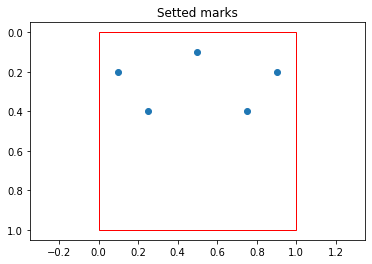

	 Setting marks ended time = 0.1525
	 Converting marks object to a landpy heat started 
		 Setting heat started 


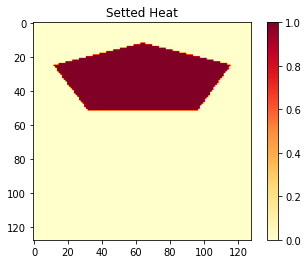

			 Setting flow_data started 
			 Setting flow_data ended time = 0.0000
		 Setting heat ended time = 0.2110
	 Converting marks object to a landpy heat ended time = 0.2120
	 Zooming in heat started 
		 Making trace started 
		 Making trace ended time = 0.0000
		 Heat before zoom saved! time = 0.0000
		 Image after zoom saved! time = 0.0020


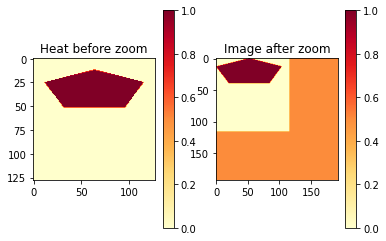

	 Zooming in heat ended time = 0.2691
	 Showing the heat started 


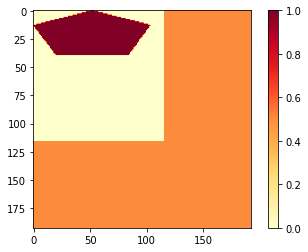

	 Showing the heat ended time = 0.1680


In [1]:
from landpy import MarksLand, Debugger, SquareMarks

import numpy as np
debugger = Debugger(debug=True, textual_debug=True, visual_debug=True, categories=[])
marks = np.array([(0.1,0.2), (0.5,0.1), (0.9,0.2), (0.75,0.4), (0.25,0.4)])
land = MarksLand(marks, debugger=debugger)
heat = land.to_heat()
heat.zoom(SquareMarks(0.1,1.6,0.1,1.6), fill_heat=0.5)
heat.show()

In [1]:
import numpy as np
np.zeros([3,4])[:].shape

(3, 4)

 Debugger init started 
	 Setting image started 


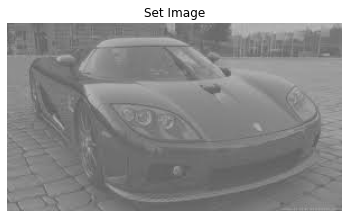

		 Setting flow_data started 
		 Setting flow_data ended time = 0.0000
	 Setting image ended time = 0.0750
	 Showing the image started 


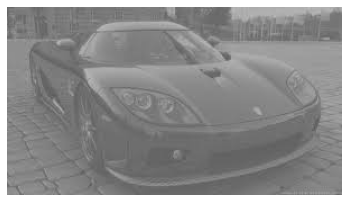

	 Showing the image ended time = 0.0970
	 Applying histogram equalization method on the image started 
		 Making trace started 
		 Making trace ended time = 0.0000
		 Image before h.e. saved! time = 0.1370
		 Image after h.e. saved! time = 0.1380


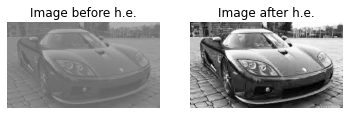

	 Applying histogram equalization method on the image ended time = 0.2140
	 Showing the image started 


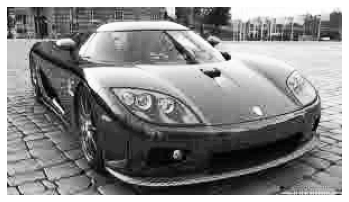

	 Showing the image ended time = 0.0670
	 Retracing land started 
		 Applying inverse of histogram equalization method on the image started 
			 Image before h.e. inverse saved! time = 0.0000
			 Image after h.e. inverse saved! time = 0.0010


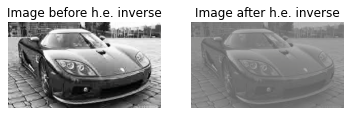

		 Applying inverse of histogram equalization method on the image ended time = 0.0980
	 Retracing land ended time = 0.0980
	 Showing the image started 


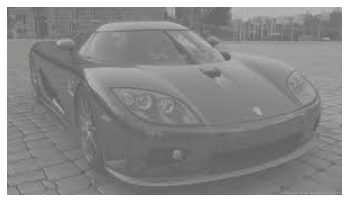

	 Showing the image ended time = 0.0630


In [1]:
import inspect
import time
from abc import ABC, abstractmethod
from typing import Callable, List, Tuple, Dict, Literal, Any, Iterable
from landpy import ImageLand, Debugger, QuadMarks, SquareMarks
from PIL import Image
import numpy as np
import time
import matplotlib.pylab as plt

image = np.array(Image.open('test2.jpg').convert('RGB'))
land = ImageLand(debugger=Debugger(debug=True, textual_debug=True, visual_debug=True))
land.set_image(image)
land.show()
land.equalize_histogram()
land.show()
land.retrace()
land.show()


 Debugger init started 
	 Setting image started 
		 Setting flow_data started 
		 Setting flow_data ended time = 0.0000
	 Setting image ended time = 0.0029
	 Zooming in image started 
		 Making trace started 
		 Making trace ended time = 0.0000
	 Zooming in image ended time = 0.0020
	 Zooming in image started 
		 Making trace started 
		 Making trace ended time = 0.0000
	 Zooming in image ended time = 0.0111
	 Rotating image started 
		 (angle, center) = (60, (420, 280)) time = 0.0000
	 Rotating image ended time = 0.0055
	 Retracing land started 
		 Zooming back image started 
		 Zooming back image ended time = 0.0065
	 Retracing land ended time = 0.0065
	 Retracing land started 
		 Zooming back image started 
		 Zooming back image ended time = 0.0070
	 Retracing land ended time = 0.0070
	 Zooming in image started 
		 Making trace started 
		 Making trace ended time = 0.0000
	 Zooming in image ended time = 0.0015
	 implanting filter in image started 
	 implanting filter in image ended 

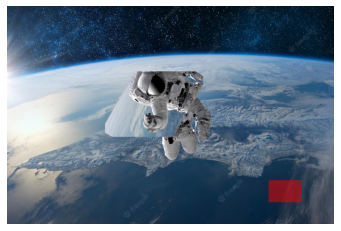

	 Showing the image ended time = 0.2501
 Debugger init ended time = 0.2912


In [2]:
import inspect
import time
from abc import ABC, abstractmethod
from typing import Callable, List, Tuple, Dict, Literal, Any, Iterable
from landpy import ImageLand, Debugger, QuadMarks, SquareMarks
from PIL import Image
import numpy as np
import time
import matplotlib.pylab as plt

image = np.array(Image.open('test.jpg').convert('RGBA'))

land = ImageLand(debugger=Debugger(debug=True, textual_debug=True, visual_debug=False))
land.set_image(image)
st_time = time.time()

land.zoom(SquareMarks(0.3,0.6,0.3,0.6), fill_color=(255,0,0,0))
land.zoom(SquareMarks(-0.2,1.2,-0.2,1.2), fill_color=(255,0,0,0))
land.rotate(60, save_trace=False, fill_color=(0,255,0,0))
land.retrace()
land.retrace()

land.zoom(SquareMarks(0.8,0.9,0.8,0.9), fill_color=(255,0,0,0))
land.implant_filter(None)
land.retrace()

land.show()
del land


 Debugger init started 
	 Setting image started 
		 Setting flow_data started 
		 Setting flow_data ended time = 0.0000
	 Setting image ended time = 0.0025
	 Zooming in image started 
		 Making trace started 
		 Making trace ended time = 0.0000
	 Zooming in image ended time = 0.0035
	 Zooming in image started 
		 Making trace started 
		 Making trace ended time = 0.0000
	 Zooming in image ended time = 0.0100
	 Rotating image started 
		 (angle, center) = (60, (420, 280)) time = 0.0000
	 Rotating image ended time = 0.0020
	 Retracing land started 
		 Zooming back image started 
		 Zooming back image ended time = 0.0070
	 Retracing land ended time = 0.0070
	 Retracing land started 
		 Zooming back image started 
		 Zooming back image ended time = 0.0060
	 Retracing land ended time = 0.0070
	 Zooming in image started 
		 Making trace started 
		 Making trace ended time = 0.0000
	 Zooming in image ended time = 0.0025
	 implanting filter in image started 
	 implanting filter in image ended 

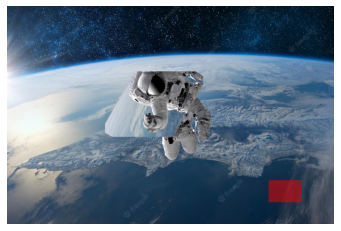

	 Showing the image ended time = 0.2479
 Debugger init ended time = 0.2854


In [3]:
import inspect
import time
from abc import ABC, abstractmethod
from typing import Callable, List, Tuple, Dict, Literal, Any, Iterable
from landpy import ImageLand, Debugger, QuadMarks, SquareMarks
from PIL import Image
import numpy as np
import time
import matplotlib.pylab as plt

image = np.array(Image.open('test.jpg').convert('RGBA'))

land = ImageLand(debugger=Debugger(debug=True, textual_debug=True, visual_debug=False))
land.set_image(image)
st_time = time.time()

land.zoom(SquareMarks(0.3,0.6,0.3,0.6), fill_color=(255,0,0,0))
land.zoom(SquareMarks(-0.2,1.2,-0.2,1.2), fill_color=(255,0,0,0))
land.rotate(60, save_trace=False, fill_color=(0,255,0,0))
land.retrace()
land.retrace()

land.zoom(SquareMarks(0.8,0.9,0.8,0.9), fill_color=(255,0,0,0))
land.implant_filter(None)
land.retrace()

land.show()
del land


 Setting image started 


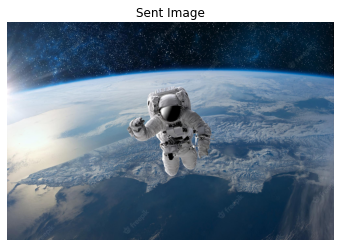

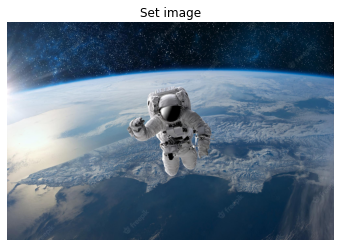

 Setting image ended time = 1.2193
 Setting image started 


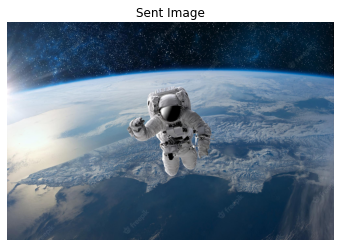

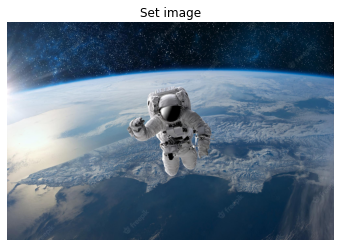

 Setting image ended time = 1.1953
 Reshaping image started 
	 (w, h, mode) = (100, 120, RGB) time = 0.0000
	 Image before reshape saved! time = 0.0080
	 Image after reshape saved! time = 0.0370


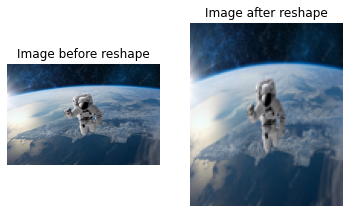

 Reshaping image ended time = 0.6041
 Showing the image started 


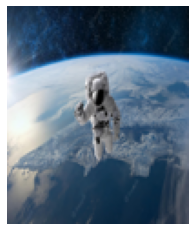

 Showing the image ended time = 0.1100
 Showing the image started 


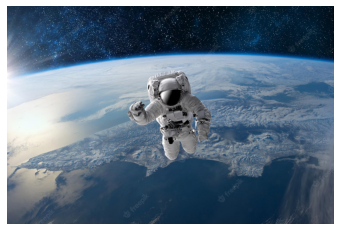

 Showing the image ended time = 0.5987


In [2]:
# Test case 1
from PIL import Image
import importlib
import landpy
from landpy import ImageLand, Debugger
import numpy as np
import matplotlib.pyplot as plt



image = np.array(Image.open('test.jpg'))
debugger = Debugger(textual_debug=True, visual_debug=True, show_file=False, show_line=False,
                   categories=['ImageLand'])
land = ImageLand(image, debugger)
land.set_image(image)

land.make_checkpoint()
ll = land.copy()
land.reshape((100,120))
land.show()
ll.show()
del land
del debugger

In [ ]:
find one face

find multiple faces

edite lab insta
lip landmark -> zoom in lip -> get lip image 
-> get lip segm by model or landmark (.to_heat) (secend is better)
-> spread lip landmarks -> put lip image-segm in spearded dots location


In [10]:
import numpy as np
x = np.random.random([10])
y = np.random.random([10])

 Debugger init started 
	 Setting marks started 
		 Converting to (n,2) matrix started 
		 Converting to (n,2) matrix ended time = 0.0000
		 Setting flow_data started 
		 Setting flow_data ended time = 0.0000
	 Setting marks ended time = 0.0000
	 Zooming marks started 
		 Making trace started 
		 Making trace ended time = 0.0000
		 Marks before zoom! saved! time = 0.0000
		 Marks after zoom! saved! time = 0.0000


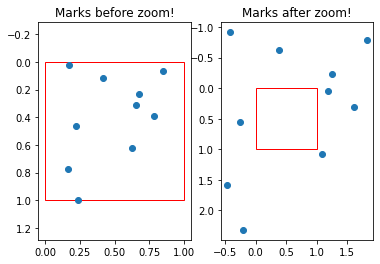

	 Zooming marks ended time = 0.1372
	 Retracing land started 
		 Zooming back marks started 
			 Marks before zoom back! saved! time = 0.0000
			 Marks after zoom back! saved! time = 0.0013


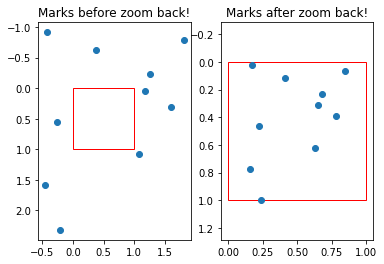

		 Zooming back marks ended time = 0.1481
	 Retracing land ended time = 0.1481
 Debugger init ended time = 0.2863


In [11]:
# Test case 2
from PIL import Image
import importlib
import landpy
from landpy import MarksLand, Debugger, SquareMarks
import numpy as np
import matplotlib.pyplot as plt

land = MarksLand(debugger=Debugger(textual_debug=True, visual_debug=True, show_file=False, show_line=False))

land.set_marks(x,y)

land.zoom(SquareMarks(0.3,0.6,0.3,0.6))
land.retrace()

del land

[Temp/ipykernel_24324/2216507715.py/line 7] Debugger init started 
	[debugger.py/line 396] Setting marks started 
		[debugger.py/line 420] Converting to (n,2) matrix started 
		[debugger.py/line 422] Converting to (n,2) matrix ended time = 0.0055
		[debugger.py/line 396] Setting flow_data started 
		[debugger.py/line 398] Setting flow_data ended time = 0.0070
	[debugger.py/line 398] Setting marks ended time = 0.0311
	[debugger.py/line 396] Showing marks started 


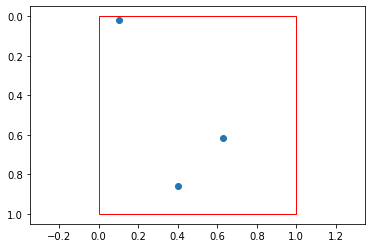

	[debugger.py/line 398] Showing marks ended time = 0.0825
	[debugger.py/line 396] Converting MarksLand to SquareMarks started 
	[debugger.py/line 398] Converting MarksLand to SquareMarks ended time = 0.0060


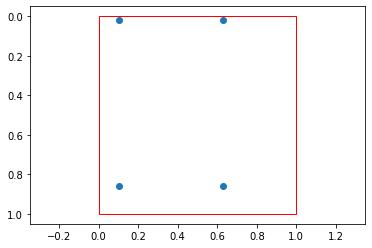

In [12]:
from landpy import MarksLand, Debugger
import numpy as np

x = list(np.random.rand(3))
y = list(np.random.rand(3))

land = MarksLand(debugger=Debugger(textual_debug=True, 
                          visual_debug=True, 
                          show_file=True, 
                          show_line=True))

land.set_marks(x,y)

land.show()
land = land.to_square()
land.show()


[Temp/ipykernel_24324/2569304771.py/line 6] Debugger init started 
	[debugger.py/line 396] Setting marks started 
		[debugger.py/line 420] Converting to (n,2) matrix started 
		[debugger.py/line 422] Converting to (n,2) matrix ended time = 0.0070
		[debugger.py/line 396] Setting flow_data started 
		[debugger.py/line 398] Setting flow_data ended time = 0.0056
	[debugger.py/line 398] Setting marks ended time = 0.0317
	[debugger.py/line 396] Showing marks started 


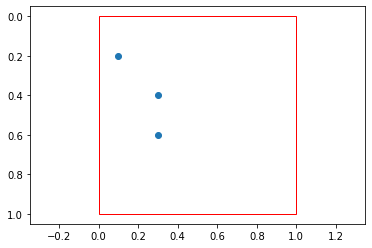

	[debugger.py/line 398] Showing marks ended time = 0.0817
[Temp/ipykernel_24324/2569304771.py/line 15] Debugger init started 
	[debugger.py/line 396] Setting marks started 
		[debugger.py/line 420] Converting to (n,2) matrix started 
		[debugger.py/line 422] Converting to (n,2) matrix ended time = 0.0065
		[debugger.py/line 396] Setting flow_data started 
		[debugger.py/line 398] Setting flow_data ended time = 0.0065
	[debugger.py/line 398] Setting marks ended time = 0.0359
	[debugger.py/line 396] Showing marks started 


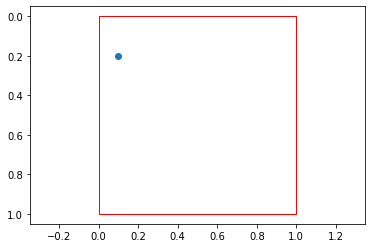

	[debugger.py/line 398] Showing marks ended time = 0.0802
(1, 2)


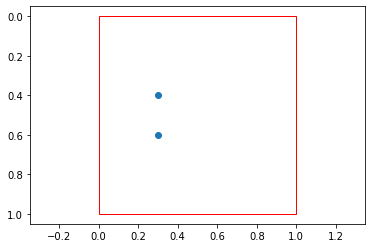

In [13]:
from landpy import MarksLand, Debugger
import numpy as np

x = [(0.1,0.2), (0.3,0.4), (0.3,0.6)]

land = MarksLand(debugger=Debugger(textual_debug=True, 
                          visual_debug=True, 
                          show_file=True, 
                          show_line=True))
land.set_marks(x)
land.show()

x = [(0.1,0.2)]

land2 = MarksLand(debugger=Debugger(textual_debug=True, 
                          visual_debug=True, 
                          show_file=True, 
                          show_line=True))
land2.set_marks(x)
land2.show()
print(land2._flow_data.shape)
land3 = land-land2
land3.show()



 Setting marks started 
	 Converting to (n,2) matrix started 
	 Converting to (n,2) matrix ended time = 0.0005
 Setting marks ended time = 0.0005
 Showing marks started 


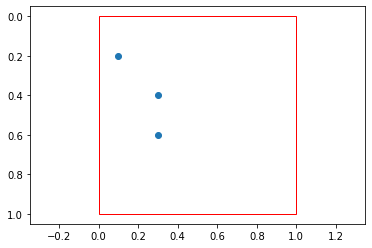

 Showing marks ended time = 0.0701


In [14]:
from PIL import Image
import importlib
import landpy
from landpy import MarksLand, Debugger, SquareMarks
import numpy as np
import matplotlib.pyplot as plt
x = [(0.1,0.2), (0.3,0.4), (0.3,0.6)]

land = MarksLand(x, debugger=Debugger(textual_debug=True, 
                          visual_debug=True, 
                          show_file=False, 
                          show_line=False,
                          categories=['MarksLand']))


land.show()
print(land.to_heat((500,500)))
del land

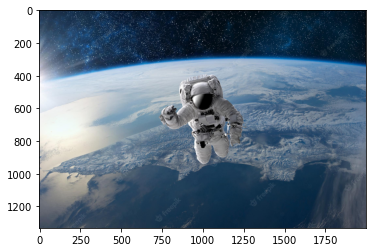

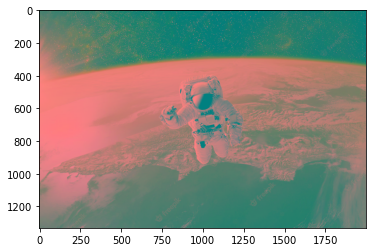

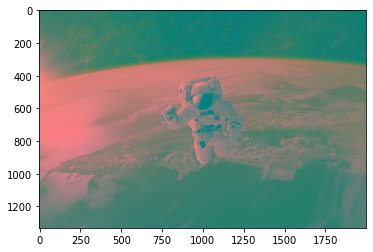

0

In [28]:
def histogram_equalization(image):    
    lab_image = cv2.cvtColor(image, cv2.COLOR_RGB2Lab)
    l_channel, a_channel, b_channel = cv2.split(lab_image)
    equ_l_channel = cv2.equalizeHist(l_channel)
    equ_lab_image = cv2.merge((equ_l_channel, a_channel, b_channel))
    #equalized_image = cv2.cvtColor(equ_lab_image, cv2.COLOR_Lab2RGB)
    return equ_lab_image, lab_image

def histogram_equalization_back(equalized_image, original_image):
    # Convert images to Lab color space
    #equ_lab_image = cv2.cvtColor(equalized_image, cv2.COLOR_RGB2Lab)
    original_lab_image = cv2.cvtColor(original_image, cv2.COLOR_RGB2Lab)

    # Split the Lab image channels
    equ_l_channel, a_channel, b_channel = cv2.split(equalized_image)
    original_l_channel, _, _ = cv2.split(original_lab_image)

    # Merge the equalized L channel with the original A and B channels
    back_lab_image = cv2.merge((original_l_channel, a_channel, b_channel))

    # Convert image back to BGR color space
    #back_image = cv2.cvtColor(back_lab_image, cv2.COLOR_Lab2RGB)

    return back_lab_image

original_image = np.array(Image.open('test.jpg').convert('RGB'))
plt.imshow(original_image)
plt.show()

equalized_image, lab_image = histogram_equalization(original_image)
plt.imshow(equalized_image)
plt.show()

image3 = histogram_equalization_back(equalized_image, original_image)
plt.imshow(image3)
plt.show()

np.sum(np.abs(image3-lab_image))